# 402 - Deep Convolutional Models: Case Studies

## Table of Contents
[1.2. Building Neural Networks with PyTorch](#Building-Neural-Networks-with-PyTorch)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.1. PyTorch Fundamentals](#PyTorch-Fundamentals)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.2. Implementing Linear Regression](#Implementing-Linear-Regression)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.3. Implementing a Regression MLP](#Implementing-a-Regression-MLP)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.4. Implementing Mini-Batch Gradient Descent Using DataLoaders](#Implementing-Mini-Batch-Gradient-Descent-Using-DataLoaders)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.5. Model Evaluation](#Model-Evaluation)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.6. Building Nonsequential Models Using Custom Modules](#Building-Nonsequential-Models-Using-Custom-Modules)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.7. Building an Image Classifier with PyTorch](#Building-an-Image-Classifier-with-PyTorch)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.8. Fine-Tuning Neural Network Hyperparameters with Optuna](#Fine-Tuning-Neural-Network-Hyperparameters-with-Optuna)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.9. Saving and Loading PyTorch Models](#Saving-and-Loading-Pytorch-Models)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.10. Exercise (fully connected module)](#Exercise-(fully-connected-module))<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.2.11. Exercise (CoverType dataset)](#Exercise-(CoverType-dataset))<br>
[1.3. Training Deep Neural Networks](#Training-Deep-Neural-Networks)<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;[1.3.1. Exercise (CIFAR 10)](#Exercise-(CIFAR-10))<br>

<div style="background-color: #ffe6e6; border-left: 5px solid #ff4d4d; padding: 15px; border-radius: 4px; color: #333;">
  <strong>Note:</strong> Before going over this week's programming assignments, I'm going to study Chapters 10 and 11 from Geron's <i>Hands-on Machine Learning with Scikit-Learn and PyTorch.</i> To learn how to implement models using PyTorch's high-level API.
</div>

In [1]:
# Standard Imports
import numpy as np
import matplotlib.pyplot as plt
import torch

## Building Neural Networks with PyTorch

### PyTorch Fundamentals

In [2]:
# Check available devices
if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'
print(device)

mps


In [3]:
# Hardware Accelarators: GPU vs CPU (Hydrogen bomb vs. coughing baby)
# CPU
M = torch.rand((1000,1000))
%timeit M @ M.T

# GPU
M = torch.rand((1000,1000), device='mps')
%timeit M @ M.T

2.54 ms ± 420 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)
2 ms ± 315 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [4]:
# Autograd - Optimizing a quadratic function
learning_rate = 0.01
x = torch.tensor(-15., requires_grad=True, device=device)
y = torch.tensor(-19., requires_grad=True, device=device)
x_data = [x.detach().cpu()]
y_data = [y.detach().cpu()]
for iteration in range(100):
    f = x**2 + 10*y**2     # Forward
    f.backward()        # Backward

    # Update
    with torch.no_grad():
        x -= learning_rate * x.grad
        y -= learning_rate * y.grad

    # Log data
    x_data.append(x.detach().cpu())
    y_data.append(y.detach().cpu())

    # Reset grads
    x.grad.zero_()
    y.grad.zero_()

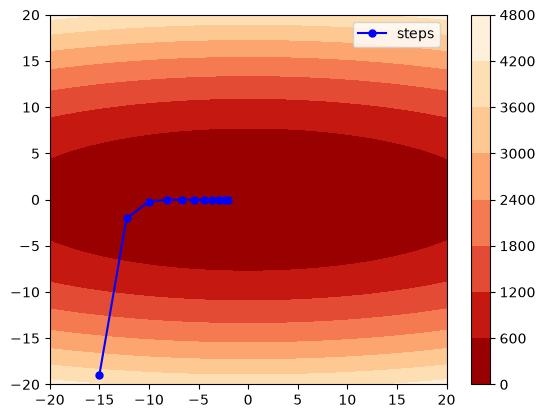

In [5]:
# Plot results
N = 100
xx = np.linspace(-20.0, 20.0, N)
yy = np.linspace(-20.0, 20.0, N)
XX, YY = np.meshgrid(xx, yy)
z = XX**2 + 10*YY**2
fig, ax = plt.subplots()
cs = ax.contourf(XX, YY, z, cmap="OrRd_r")
cbar = fig.colorbar(cs)

ax.plot(x_data[::10], y_data[::10], marker='o', ms = 5, linestyle='-', color='blue', label='steps')
ax.legend()
plt.show()

### Implementing Linear Regression

In [6]:
# Data - California Housing
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from pathlib import Path
X, y = fetch_california_housing(data_home=Path.cwd().joinpath('data'),
                                download_if_missing=True,
                                return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, random_state=42)

print('X_train shape:', X_train.shape)
print('y_train shape:', y_train.shape)
print('X_val shape:', X_val.shape)
print('y_val shape:', y_val.shape)
print('X_test shape:', X_test.shape)
print('y_test shape:', y_test.shape)

X_train shape: (11610, 8)
y_train shape: (11610,)
X_val shape: (3870, 8)
y_val shape: (3870,)
X_test shape: (5160, 8)
y_test shape: (5160,)


In [7]:
# Preprocessing - Tensorize and Scale
X_train = torch.FloatTensor(X_train)
X_val = torch.FloatTensor(X_val)
X_test = torch.FloatTensor(X_test)
means = X_train.mean(dim=0, keepdim=True)
stds = X_train.std(dim=0, keepdim=True)
X_train = (X_train - means) / stds
X_val = (X_val - means) / stds
X_test = (X_test - means) / stds

y_train = torch.FloatTensor(y_train).reshape(-1,1)
y_val = torch.FloatTensor(y_val).reshape(-1,1)
y_test = torch.FloatTensor(y_test).reshape(-1,1)

print(f'X_train means (are all close to zero?):', torch.allclose(X_train.mean(), torch.tensor(0.0)))
print('X_train std (are all close to one?):', torch.allclose(X_train.std(dim=0), torch.tensor(1.0)))
print('y_train shape:', y_train.shape)
print('y_val shape:', y_val.shape)
print('y_test shape:', y_test.shape)

X_train means (are all close to zero?): False
X_train std (are all close to one?): True
y_train shape: torch.Size([11610, 1])
y_val shape: torch.Size([3870, 1])
y_test shape: torch.Size([5160, 1])


#### Using Tensors and Autograd

In [8]:
# Initialize Parameters
torch.manual_seed(42)
n_in = X_train.shape[1]
W = torch.randn((n_in, 1), requires_grad=True, device=device)
b = torch.tensor(0., requires_grad=True, device=device)

print('W.shape:', W.shape)
print('b.shape:', b.shape)
print('W\n', W)
print('b\n', b)

W.shape: torch.Size([8, 1])
b.shape: torch.Size([])
W
 tensor([[ 1.7563],
        [-0.2539],
        [-0.9927],
        [-0.6515],
        [-0.4827],
        [-0.1972],
        [ 0.4944],
        [ 0.2693]], device='mps:0', requires_grad=True)
b
 tensor(0., device='mps:0', requires_grad=True)


In [9]:
# Training
learning_rate = 0.4
epochs = 20

for iteration in range(epochs):
    # Forward
    y_train_pred = torch.matmul(X_train.to(device), W) + b
    mse_cost = ((y_train_pred - y_train.to(device))**2).mean(dim=0, keepdim=True)

    # Backward
    mse_cost.backward()

    with torch.no_grad():
        # Weight update
        W -= learning_rate * W.grad
        b -= learning_rate * b.grad

        # Reset grads
        W.grad.zero_()
        b.grad.zero_()

    print(f"Epoch {iteration + 1}/{epochs}, MSE: {mse_cost.item()}")

Epoch 1/20, MSE: 7.979630947113037
Epoch 2/20, MSE: 1.3271334171295166
Epoch 3/20, MSE: 0.8188684582710266
Epoch 4/20, MSE: 0.7123925685882568
Epoch 5/20, MSE: 0.6727660298347473
Epoch 6/20, MSE: 0.6517985463142395
Epoch 7/20, MSE: 0.6373873949050903
Epoch 8/20, MSE: 0.6258752346038818
Epoch 9/20, MSE: 0.6160195469856262
Epoch 10/20, MSE: 0.6073315143585205
Epoch 11/20, MSE: 0.5995773077011108
Epoch 12/20, MSE: 0.5926181077957153
Epoch 13/20, MSE: 0.5863552093505859
Epoch 14/20, MSE: 0.5807100534439087
Epoch 15/20, MSE: 0.5756163001060486
Epoch 16/20, MSE: 0.5710160136222839
Epoch 17/20, MSE: 0.566858172416687
Epoch 18/20, MSE: 0.5630974769592285
Epoch 19/20, MSE: 0.5596936345100403
Epoch 20/20, MSE: 0.5566105246543884


In [10]:
# Validation and Test
with torch.no_grad():
    y_val_pred = torch.matmul(X_val, W.cpu()) + b.cpu()
    mse_val = ((y_val_pred - y_val)**2).mean(dim=0, keepdim=True)
    print(f'Validation MSE: {mse_val.item():.3f}')

    y_test_pred = torch.matmul(X_test, W.cpu()) + b.cpu()
    mse_test = ((y_test_pred - y_test)**2).mean(dim=0, keepdim=True)
    print(f'Test MSE: {mse_test.item():.3f}')

Validation MSE: 1.179
Test MSE: 0.563


#### Using PyTorch's High-Level API

In [11]:
# Instantiation of Module
import torch.nn as nn
torch.manual_seed(42)
model = nn.Linear(in_features=n_in, out_features=1, bias=True)

print(model.bias)
print(model.weight)

# Sample prediction
print('prediction:\n', model(X_train[:2]))
print('actual:\n', y_train[:2])

Parameter containing:
tensor([0.3117], requires_grad=True)
Parameter containing:
tensor([[ 0.2703,  0.2935, -0.0828,  0.3248, -0.0775,  0.0713, -0.1721,  0.2076]],
       requires_grad=True)
prediction:
 tensor([[-0.4718],
        [ 0.1131]], grad_fn=<AddmmBackward0>)
actual:
 tensor([[1.4420],
        [1.6870]])


In [12]:
# Training
def train_bgd(model, optimizer, criterion, X_train, y_train, n_epochs):
    for epoch in range(n_epochs):
        y_pred = model(X_train)
        loss = criterion(y_pred, y_train)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        print(f'Epoch {epoch + 1}/{n_epochs}, Loss: {loss.item()}')

optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
mse = nn.MSELoss()
train_bgd(model, optimizer, mse, X_train, y_train, 20)

Epoch 1/20, Loss: 4.337850093841553
Epoch 2/20, Loss: 0.780293345451355
Epoch 3/20, Loss: 0.6253840923309326
Epoch 4/20, Loss: 0.6060433983802795
Epoch 5/20, Loss: 0.595629870891571
Epoch 6/20, Loss: 0.5873566269874573
Epoch 7/20, Loss: 0.5802990198135376
Epoch 8/20, Loss: 0.5741382241249084
Epoch 9/20, Loss: 0.5687101483345032
Epoch 10/20, Loss: 0.5639079213142395
Epoch 11/20, Loss: 0.5596511363983154
Epoch 12/20, Loss: 0.555873692035675
Epoch 13/20, Loss: 0.5525193810462952
Epoch 14/20, Loss: 0.5495391488075256
Epoch 15/20, Loss: 0.5468899011611938
Epoch 16/20, Loss: 0.544533908367157
Epoch 17/20, Loss: 0.5424376726150513
Epoch 18/20, Loss: 0.5405715703964233
Epoch 19/20, Loss: 0.5389097332954407
Epoch 20/20, Loss: 0.5374288558959961


In [13]:
# Validation and Test
with torch.no_grad():
    y_val_pred = model(X_val)
    mse_val = mse(y_val_pred, y_val)
    print(f'Validation MSE: {mse_val.item():.3f}')

    y_test_pred = model(X_test)
    mse_test = mse(y_test_pred, y_test)
    print(f'Test MSE: {mse_test.item():.3f}')

Validation MSE: 1.169
Test MSE: 0.538


### Implementing a Regression MLP

In [14]:
# Instantiate model, optimizer, and loss function
torch.manual_seed(42)
learning_rate = 0.1
model = nn.Sequential(
    nn.Linear(n_in, 50),
    nn.ReLU(),
    nn.Linear(50, 40),
    nn.ReLU(),
    nn.Linear(40, 1),
)
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
mse = nn.MSELoss()

In [15]:
# Training
train_bgd(model, optimizer, mse, X_train, y_train, 20)

Epoch 1/20, Loss: 5.045480251312256
Epoch 2/20, Loss: 2.0523128509521484
Epoch 3/20, Loss: 1.0039883852005005
Epoch 4/20, Loss: 0.8570139408111572
Epoch 5/20, Loss: 0.7740675210952759
Epoch 6/20, Loss: 0.7225847244262695
Epoch 7/20, Loss: 0.6893725991249084
Epoch 8/20, Loss: 0.6669032573699951
Epoch 9/20, Loss: 0.650773823261261
Epoch 10/20, Loss: 0.6383934617042542
Epoch 11/20, Loss: 0.6281994581222534
Epoch 12/20, Loss: 0.6193398833274841
Epoch 13/20, Loss: 0.6113173365592957
Epoch 14/20, Loss: 0.6038705706596375
Epoch 15/20, Loss: 0.5968307852745056
Epoch 16/20, Loss: 0.5901119112968445
Epoch 17/20, Loss: 0.583646833896637
Epoch 18/20, Loss: 0.5774063467979431
Epoch 19/20, Loss: 0.5713555216789246
Epoch 20/20, Loss: 0.565444827079773


In [16]:
# Validation and Testing
with torch.no_grad():
    y_val_pred = model(X_val)
    mse_val = mse(y_val_pred, y_val)
    print(f'Validation MSE: {mse_val.item():.3f}')
    y_test_pred = model(X_test)
    mse_test = mse(y_test_pred, y_test)
    print(f'Test MSE: {mse_test.item():.3f}')

Validation MSE: 0.528
Test MSE: 0.550


### Implementing Mini-Batch Gradient Descent Using DataLoaders
For PyTorch's `torch.utils.data.DataLoader` to work, the dataset must have at least two methods: `__len__(self)` and `__getitem__(self, index)`. Tensors have these.

In [17]:
# Check dataset attributes
print('X_train has __len__ method:', hasattr(X_train, '__len__'))
print('X_train has __getitem__ method:', hasattr(X_train, '__getitem__'))

X_train has __len__ method: True
X_train has __getitem__ method: True


In [18]:
# Wrapping in dataset object and creating data loader
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

In [24]:
# Training with Minibatch GD
torch.manual_seed(42)
learning_rate = 0.02
model = nn.Sequential(
    nn.Linear(n_in, 50),
    nn.ReLU(),
    nn.Linear(50, 40),
    nn.ReLU(),
    nn.Linear(40, 1),
).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
mse = nn.MSELoss().to(device)

def train_mbgd(model, dataloader, optimizer, criterion, n_epochs, device='mps'):
    model.train()   # Training mode??? idk...
    training_loss = 0
    for epoch in range(n_epochs):
        for X_mb, y_mb in dataloader:
            X_mb = X_mb.to(device)
            y_mb = y_mb.to(device)
            y_out = model(X_mb)
            loss = criterion(y_out, y_mb)
            training_loss += loss.detach().item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        training_loss /= len(dataloader)
        print(f'Epoch {epoch + 1}/{n_epochs}, Loss: {training_loss}')

train_mbgd(model, train_loader, optimizer, mse, 20, device)

Epoch 1/20, Loss: 0.5900079323486849
Epoch 2/20, Loss: 0.4061779712592483
Epoch 3/20, Loss: 0.3812384937187624
Epoch 4/20, Loss: 0.36399858942564434
Epoch 5/20, Loss: 0.35395028213635116
Epoch 6/20, Loss: 0.35292508844529014
Epoch 7/20, Loss: 0.34174172698312977
Epoch 8/20, Loss: 0.3436398516459585
Epoch 9/20, Loss: 0.34157983160581673
Epoch 10/20, Loss: 0.33871020688516285
Epoch 11/20, Loss: 0.33129854696140426
Epoch 12/20, Loss: 0.3276047966094151
Epoch 13/20, Loss: 0.3252722771716762
Epoch 14/20, Loss: 0.3229812997970241
Epoch 15/20, Loss: 0.3195004755727607
Epoch 16/20, Loss: 0.31573567385364615
Epoch 17/20, Loss: 0.3131371998998988
Epoch 18/20, Loss: 0.3119330401575526
Epoch 19/20, Loss: 0.30970756688923545
Epoch 20/20, Loss: 0.3080520996453899


In [32]:
# Validation and Testing
with torch.no_grad():
    y_val_pred = model.to('cpu')(X_val)
    mse_val = mse(y_val_pred, y_val)
    print(f'Validation MSE: {mse_val.item():.3f}')
    y_test_pred = model.to('cpu')(X_test)
    mse_test = mse(y_test_pred, y_test)
    print(f'Test MSE: {mse_test.item():.3f}')

Validation MSE: 0.408
Test MSE: 0.312


### Model Evaluation

In [33]:
# Define Evaluator
from collections.abc import Callable

def evaluate(model, loader, metric_fn, agg_fn: Callable = torch.mean, device='mps'):
    model.eval()
    metrics = []
    with torch.no_grad():
        for X_mb, y_mb in loader:
            X_mb, y_mb = X_mb.to(device), y_mb.to(device)
            y_pred = model(X_mb)
            metric = metric_fn(y_pred, y_mb)
            metrics.append(metric)
    return agg_fn(torch.stack(metrics))

In [34]:
# Build Validation Dataset
val_dataset = TensorDataset(X_val, y_val)
val_loader = DataLoader(val_dataset, batch_size=32)

In [35]:
# Validation with MSE
val_mse = evaluate(model.to(device), val_loader, mse)
print(f'Validation MSE: {val_mse.item():.3f}')

Validation MSE: 0.408


In [36]:
# Validation with RMSE
val_rmse = evaluate(model, val_loader, mse, lambda metrics: torch.sqrt(torch.mean(metrics)))
print(f'Validation RMSE: {val_rmse.item():.3f}')

Validation RMSE: 0.639


In [37]:
# Implementation with TorchMetrics
from torchmetrics import MeanSquaredError, Metric

def evaluate_tm(model, loader, metric_fn: Metric, device='mps'):
    model.eval()
    metric_fn.reset()
    with torch.no_grad():
        for X_mb, y_mb in loader:
            X_mb, y_mb = X_mb.to(device), y_mb.to(device)
            y_pred = model(X_mb)
            metric_fn.update(y_pred, y_mb)
    return metric_fn.compute()

# with MSE
mse_tm = MeanSquaredError().to(device)
val_mse = evaluate_tm(model, val_loader, mse_tm)

# with RMSE
rmse_tm = MeanSquaredError(squared=False).to(device)
val_rmse = evaluate_tm(model, val_loader, rmse_tm)

print(f'Validation MSE: {val_mse.item():.3f}')
print(f'Validation RMSE: {val_rmse.item():.3f}')

Validation MSE: 0.408
Validation RMSE: 0.639


### Building Nonsequential Models Using Custom Modules

#### Example: Wide and deep neural network
<img src="references/Screenshot%202026-11-03%20at%203.03.30%E2%80%AFAM.png" width=600></img><br>
*Image taken from Geron's book*

It is useful to have a wide part to learn simple rules about the data, and a deep part that learns the complex patterns.

By concatenating the input with the output of the deep part, it would be like the network is fitting both a simple linear model and a more complex MLP model.

In [39]:
# Create wide and deep neural network as custom module
class WideAndDeep(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features, 50), nn.ReLU(),
            nn.Linear(50, 40), nn.ReLU(),
        )
        self.output_layer = nn.Linear(40 + n_features, 1)
    def forward(self, X):
        deep_out = self.deep_stack(X)
        wide_and_deep = torch.concat([deep_out, X], dim=1)
        return self.output_layer(wide_and_deep)

In [40]:
# Try-out the network
model = WideAndDeep(n_in).to(device)
learning_rate = 0.002
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
loss = nn.MSELoss()
train_mbgd(model, train_loader, optimizer, loss, 20, device)

Epoch 1/20, Loss: 1.3522043087347808
Epoch 2/20, Loss: 0.6218651010172055
Epoch 3/20, Loss: 0.5637327599496925
Epoch 4/20, Loss: 0.5371930793428473
Epoch 5/20, Loss: 0.5078988895149993
Epoch 6/20, Loss: 0.49348163984458193
Epoch 7/20, Loss: 0.4760305033511214
Epoch 8/20, Loss: 0.4650984745260951
Epoch 9/20, Loss: 0.45492301426781023
Epoch 10/20, Loss: 0.4464975834054957
Epoch 11/20, Loss: 0.4392191221152902
Epoch 12/20, Loss: 0.43250444639534635
Epoch 13/20, Loss: 0.42592880093166896
Epoch 14/20, Loss: 0.4218241275988748
Epoch 15/20, Loss: 0.41573723785357336
Epoch 16/20, Loss: 0.4109682964866012
Epoch 17/20, Loss: 0.4065839381223388
Epoch 18/20, Loss: 0.40200145617365657
Epoch 19/20, Loss: 0.3981440361230071
Epoch 20/20, Loss: 0.39392260361360576


In [41]:
# Validate and Test
test_dataset = TensorDataset(X_test, y_test)
test_loader = DataLoader(test_dataset, batch_size=32)

val_mse = evaluate_tm(model, val_loader, mse_tm, device)
test_mse = evaluate_tm(model, test_loader, mse_tm, device)

print(f'Validation MSE: {val_mse.item():.3f}')
print(f'Test MSE: {test_mse.item():.3f}')

Validation MSE: 0.547
Test MSE: 0.397


#### Building Models with Multiple Inputs

Sometimes we want different subsets of the features as inputs to the deep and wide parts. And they do not necessarily have the same dimensions, e.g., text as input to the wide part and image to the deep part.<br>
<img src="references/Screenshot 2026-11-03 at 3.34.41 AM.png" width=600></img><br>
*Image taken from Geron's book*

In [42]:
# create a dataset subclass for deep and wide
class WideAndDeepDataset(torch.utils.data.Dataset):
    def __init__(self, X_wide, X_deep, y):
        self.X_wide = X_wide
        self.X_deep = X_deep
        self.y = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, index):
        input_dict = {"X_wide": self.X_wide[index], "X_deep": self.X_deep[index]}
        return input_dict, self.y[index]

# Modifying Wide and Deep class
class WideAndDeepV2(nn.Module):
    def __init__(self, n_features_wide, n_features_deep):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features_deep, 50), nn.ReLU(),
            nn.Linear(50, 40), nn.ReLU(),
        )
        self.output_layer = nn.Linear(40 + n_features_wide, 1)
    def forward(self, X_wide, X_deep):
        deep_out = self.deep_stack(X_deep)
        wide_and_deep = torch.concat([X_wide, deep_out], dim=1)
        return self.output_layer(wide_and_deep)

# modify training function
def train_mbgd_v2(model, dataloader, optimizer, criterion, n_epochs, device='mps'):
    model.train()
    training_loss = 0
    for epoch in range(n_epochs):
        for X_mb, y_mb in dataloader:
            X_mb = {name: X.to(device) for name, X in X_mb.items()}
            y_mb = y_mb.to(device)
            y_out = model(**X_mb)
            loss = criterion(y_out, y_mb)
            training_loss += loss.detach().item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        training_loss /= len(dataloader)
        print(f'Epoch {epoch + 1}/{n_epochs}, Loss: {training_loss}')

# modify evaluation function
def evaluate_tm_v2(model, loader, metric_fn: Metric, device='mps'):
    model.eval()
    metric_fn.reset()
    with torch.no_grad():
        for X_mb, y_mb in loader:
            X_mb, y_mb = {name: X.to(device) for name, X in X_mb.items()}, y_mb.to(device)
            y_pred = model(**X_mb)
            metric_fn.update(y_pred, y_mb)
    return metric_fn.compute()

In [43]:
# Prepare dataset and loader
features_wide = [0,1,2,3,4]
features_deep = [2, 3, 4, 5, 6, 7]

# Training data
X_wide_train = X_train[:,features_wide]
X_deep_train = X_train[:,features_deep]
train_dataset = WideAndDeepDataset(X_wide_train, X_deep_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# Validation data
X_wide_val = X_train[:,features_wide]
X_deep_val = X_train[:,features_deep]
val_dataset = WideAndDeepDataset(X_wide_val, X_deep_val, y_train)
val_loader = DataLoader(val_dataset, batch_size=32)

# Test data
X_wide_test = X_test[:,features_wide]
X_deep_test = X_test[:,features_deep]
test_dataset = WideAndDeepDataset(X_wide_test, X_deep_test, y_test)
test_loader = DataLoader(test_dataset, batch_size=32)

In [44]:
# WideAndDeepV2 training
model = WideAndDeepV2(len(features_wide), len(features_deep)).to(device)
learning_rate = 0.002
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
loss = nn.MSELoss()
train_mbgd_v2(model, train_loader, optimizer, loss, 20, device)

Epoch 1/20, Loss: 1.5391884568473195
Epoch 2/20, Loss: 0.5796692283037336
Epoch 3/20, Loss: 0.5272533579719634
Epoch 4/20, Loss: 0.5006970269330968
Epoch 5/20, Loss: 0.4828013405690532
Epoch 6/20, Loss: 0.4710143684069671
Epoch 7/20, Loss: 0.46234163638610604
Epoch 8/20, Loss: 0.4564620598780293
Epoch 9/20, Loss: 0.45075171095188304
Epoch 10/20, Loss: 0.4458939375737826
Epoch 11/20, Loss: 0.4429824868105275
Epoch 12/20, Loss: 0.4398423691082325
Epoch 13/20, Loss: 0.43707789988597906
Epoch 14/20, Loss: 0.4338096076192957
Epoch 15/20, Loss: 0.43102575743984983
Epoch 16/20, Loss: 0.42887418505477704
Epoch 17/20, Loss: 0.42658733411752947
Epoch 18/20, Loss: 0.4245548509734317
Epoch 19/20, Loss: 0.4224014904444259
Epoch 20/20, Loss: 0.4202731259793467


In [45]:
# WideAndDeepV2 Evaluation and Testing
val_mse = evaluate_tm_v2(model, val_loader, mse_tm, device)
test_mse = evaluate_tm_v2(model, test_loader, mse_tm, device)

print(f'Validation MSE: {val_mse.item():.3f}')
print(f'Test MSE: {test_mse.item():.3f}')

Validation MSE: 0.417
Test MSE: 0.410


#### Building Models with Multiple Outputs
<img src="references/Screenshot 2026-11-04 at 3.00.23 AM.png" width=600>

Examples of use cases of multiple output networks (multitasking):
- (1) locating the main object in the picture (regression), and (2) classifying the main object (classification).
- multitask classification, e.g., identifying the person's facial expression and identifying whether they are wearing glasses or not. It is possible to train two different networks for these tasks, but a single network could be better since it can utilize information across all tasks.
- regularization, e.g., adding an auxilliary output to ensure that a subset of the layers learns something useful on its own.

In [46]:
# Example: Adding an Auxilliary Output to WideAndDeep
class WideAndDeepV3(nn.Module):
    def __init__(self, n_features_wide, n_features_deep):
        super().__init__()
        self.deep_stack = nn.Sequential(
            nn.Linear(n_features_deep, 50), nn.ReLU(),
            nn.Linear(50, 40), nn.ReLU(),
        )
        self.output_layer = nn.Linear(40 + n_features_wide, 1)
        self.aux_output_layer = nn.Linear(40, 1)
    def forward(self, X_wide, X_deep):
        deep_out = self.deep_stack(X_deep)
        wide_and_deep = torch.concat([X_wide, deep_out], dim=1)
        main_output = self.output_layer(wide_and_deep)
        aux_output = self.aux_output_layer(deep_out)
        return main_output, aux_output

# modify training function
def train_mbgd_v3(model, dataloader, optimizer, criterion, n_epochs, device='mps'):
    model.train()
    training_loss = 0
    for epoch in range(n_epochs):
        for X_mb, y_mb in dataloader:
            X_mb = {name: X.to(device) for name, X in X_mb.items()}
            y_mb = y_mb.to(device)
            y_main_out, y_aux_out = model(**X_mb)
            loss = 0.8*criterion(y_main_out, y_mb) + 0.2*criterion(y_aux_out, y_mb)
            training_loss += loss.detach().item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        training_loss /= len(dataloader)
        print(f'Epoch {epoch + 1}/{n_epochs}, Loss: {training_loss}')

# modify evaluation function
def evaluate_tm_v3(model, loader, metric_fn: Metric, device='mps'):
    model.eval()
    metric_fn.reset()
    with torch.no_grad():
        for X_mb, y_mb in loader:
            X_mb, y_mb = {name: X.to(device) for name, X in X_mb.items()}, y_mb.to(device)
            y_pred, _ = model(**X_mb)
            metric_fn.update(y_pred, y_mb)
    return metric_fn.compute()

In [47]:
# WideAndDeepV3 Training
model = WideAndDeepV3(len(features_wide), len(features_deep)).to(device)
learning_rate = 0.002
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
loss = nn.MSELoss()
train_mbgd_v3(model, train_loader, optimizer, loss, 20, device)

Epoch 1/20, Loss: 2.106518339027058
Epoch 2/20, Loss: 0.8033305085036738
Epoch 3/20, Loss: 0.7092727870915803
Epoch 4/20, Loss: 0.6663241727542545
Epoch 5/20, Loss: 0.6319786077150497
Epoch 6/20, Loss: 0.6034971988905584
Epoch 7/20, Loss: 0.5799838507899866
Epoch 8/20, Loss: 0.5597869667371795
Epoch 9/20, Loss: 0.5426992837809556
Epoch 10/20, Loss: 0.5270127888647056
Epoch 11/20, Loss: 0.5139947283437997
Epoch 12/20, Loss: 0.5026174277281112
Epoch 13/20, Loss: 0.4925100331136279
Epoch 14/20, Loss: 0.4838569594821514
Epoch 15/20, Loss: 0.4762665880978165
Epoch 16/20, Loss: 0.46982907911011995
Epoch 17/20, Loss: 0.4639998140238717
Epoch 18/20, Loss: 0.45910661113062484
Epoch 19/20, Loss: 0.45473499922991556
Epoch 20/20, Loss: 0.45148001792753367


In [48]:
# WideAndDeepV2 Evaluation and Testing
val_mse = evaluate_tm_v3(model, val_loader, mse_tm, device)
test_mse = evaluate_tm_v3(model, test_loader, mse_tm, device)

print(f'Validation MSE: {val_mse.item():.3f}')
print(f'Test MSE: {test_mse.item():.3f}')

Validation MSE: 0.407
Test MSE: 0.398


### Building an Image Classifier with PyTorch

In [49]:
# Using TorchVision to Load the Dataset
from torchvision import datasets
from torch.utils.data import random_split
import torchvision.transforms.v2 as T

# The downloaded image will be a tuple containing the input image and the label
# The dtype of the image is PIL Image, we can transform it to a torch.Image object (subclass of Tensor) via ToImage transform
# We will then use ToDtype transform for both converting the elements to float32 and scaling.
toTensor = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])

train_and_val_data = datasets.FashionMNIST(root = Path.cwd().joinpath('data'), train = True, download = True, transform = toTensor)
test_data = datasets.FashionMNIST(root=Path.cwd().joinpath('data'), train = False, download = True, transform = toTensor)

torch.manual_seed(42)
train_data, val_data = random_split(train_and_val_data, [55000, 5000])

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32)
test_loader = DataLoader(test_data, batch_size=32)

print('FashionMNIST Dataset')
print('--------------------')
print(f'  Training size: {len(train_data)}')
print(f'  Validation size: {len(val_data)}')
print(f'  Test size: {len(test_data)}')
print(f'  Example shape: {tuple(train_data[0][0].shape)}')
print(f'  Classes: {list(train_and_val_data.classes)}')

FashionMNIST Dataset
--------------------
  Training size: 55000
  Validation size: 5000
  Test size: 10000
  Example shape: (1, 28, 28)
  Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


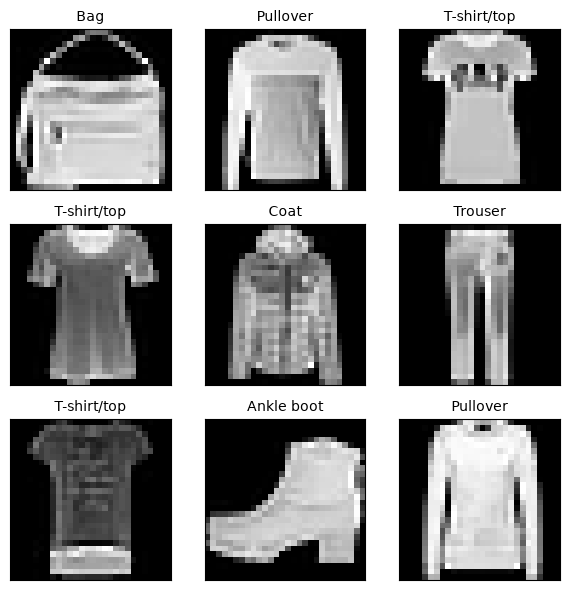

In [50]:
# Image samples
fig, axs = plt.subplots(3, 3, figsize=(6,6),
                        subplot_kw={'xticks': [], 'yticks': []},)

torch.manual_seed(42)
sample_idxs = torch.randint(0, len(train_data), (9,))
classes = train_and_val_data.classes

for i,ax in zip(sample_idxs, axs.flat):
    img, int_label = train_data[i]
    ax.imshow(img[0,:,:], cmap='gray', interpolation='nearest')
    ax.set_title(classes[int_label], fontsize=10)

fig.tight_layout()
plt.show()

In [51]:
# Define the Image Classifier
class ImageClassifier(nn.Module):
    def __init__(self, n_features, n_hidden1, n_hidden2, n_clases):
        super().__init__()
        self.model = nn.Sequential(
            nn.Flatten(),
            nn.Linear(n_features, n_hidden1), nn.ReLU(),
            nn.Linear(n_hidden1, n_hidden2), nn.ReLU(),
            nn.Linear(n_hidden2, n_clases),
        )

    def forward(self, X):
        return self.model(X)

def train_eval_mbgd(model, train_dataloader, val_dataloader, optimizer, criterion, n_epochs, device='mps'):
    training_loss = 0
    val_losses = []
    for epoch in range(n_epochs):
        model.train()
        for X_mb, y_mb in train_dataloader:
            X_mb = X_mb.to(device)
            y_mb = y_mb.to(device)
            y_out = model(X_mb)
            loss = criterion(y_out, y_mb)
            training_loss += loss.detach().item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        val_losses.append(evaluate(model, val_dataloader, criterion, device=device))
        training_loss /= len(train_dataloader)
        print(f'Epoch {epoch + 1}/{n_epochs}, Loss: {training_loss}')

    return val_losses

torch.manual_seed(42)
learning_rate = 0.001
model = ImageClassifier(28*28, 300, 100, 10).to(device)
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
val_losses = {learning_rate: train_eval_mbgd(model, train_loader, val_loader, optimizer, loss, 20, device)}

Epoch 1/20, Loss: 2.2253630061424214
Epoch 2/20, Loss: 1.8707563159295353
Epoch 3/20, Loss: 1.3588646797261352
Epoch 4/20, Loss: 1.0794391798947611
Epoch 5/20, Loss: 0.9295722185587577
Epoch 6/20, Loss: 0.8404554915885291
Epoch 7/20, Loss: 0.7821694133072542
Epoch 8/20, Loss: 0.7400795841368097
Epoch 9/20, Loss: 0.7065606357553469
Epoch 10/20, Loss: 0.6779744484628184
Epoch 11/20, Loss: 0.6536839761889467
Epoch 12/20, Loss: 0.6317051931258431
Epoch 13/20, Loss: 0.612911302831625
Epoch 14/20, Loss: 0.5957800109458722
Epoch 15/20, Loss: 0.5804798422642723
Epoch 16/20, Loss: 0.5671424194588681
Epoch 17/20, Loss: 0.5546887933886843
Epoch 18/20, Loss: 0.5439572424901253
Epoch 19/20, Loss: 0.5341335748780814
Epoch 20/20, Loss: 0.5251067516937091


In [52]:
# Find best LR
lrs = [7.5e-3, 2.0e-2, 4.0e-2]
for lr in lrs:
    model = ImageClassifier(28*28, 300, 100, 10).to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss = nn.CrossEntropyLoss()
    print(f"\n--- Starting Training with Learning Rate: {lr} ---")
    val_losses[lr] = train_eval_mbgd(model, train_loader, val_loader, optimizer, loss, 20, device)


--- Starting Training with Learning Rate: 0.0075 ---
Epoch 1/20, Loss: 1.2180495693144096
Epoch 2/20, Loss: 0.6322897318101989
Epoch 3/20, Loss: 0.536142318163283
Epoch 4/20, Loss: 0.49256558825445995
Epoch 5/20, Loss: 0.46868090429572024
Epoch 6/20, Loss: 0.45135093224251266
Epoch 7/20, Loss: 0.43521373929472684
Epoch 8/20, Loss: 0.42322801740192123
Epoch 9/20, Loss: 0.41239196395358085
Epoch 10/20, Loss: 0.40243809049738755
Epoch 11/20, Loss: 0.3931802420203149
Epoch 12/20, Loss: 0.3840917763640087
Epoch 13/20, Loss: 0.37652203902943326
Epoch 14/20, Loss: 0.3681334536191943
Epoch 15/20, Loss: 0.3615280974985554
Epoch 16/20, Loss: 0.3543637512963827
Epoch 17/20, Loss: 0.3484401709407575
Epoch 18/20, Loss: 0.3427787982212918
Epoch 19/20, Loss: 0.33642496432787805
Epoch 20/20, Loss: 0.3315672418459312

--- Starting Training with Learning Rate: 0.02 ---
Epoch 1/20, Loss: 0.8592344023777067
Epoch 2/20, Loss: 0.498693879757922
Epoch 3/20, Loss: 0.4429701194492579
Epoch 4/20, Loss: 0.41142

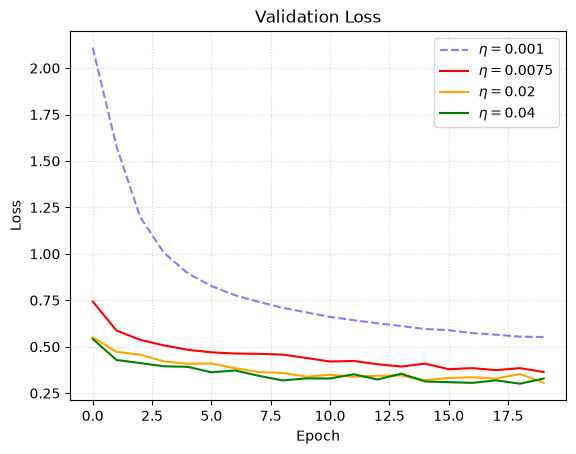

In [53]:
# Plot validation losses by LR
colors = ['blue', 'red', 'orange', 'green', 'blue', 'red', 'orange']
for color, record in zip(colors, val_losses.items()):
    lr, loss_ = record
    ls, alpha = ('-', 1.0) if lr in [7.5e-3, 2.0e-2, 4.0e-2] else ('--', 0.5)
    plt.plot(range(len(loss_)), list(map(lambda x: x.to('cpu'), loss_)), ls=ls, alpha=alpha, color=color, label=rf'$\eta=${lr}')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(visible=True, ls=':', alpha=0.5)
plt.title('Validation Loss')
plt.legend()
plt.show()

In [54]:
# Train on best LR
torch.manual_seed(42)
learning_rate = 0.02
model = ImageClassifier(28*28, 300, 100, 10).to(device)
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
val_loss = train_eval_mbgd(model, train_loader, val_loader, optimizer, loss, 20, device)

Epoch 1/20, Loss: 0.8871514641350962
Epoch 2/20, Loss: 0.5105545521298597
Epoch 3/20, Loss: 0.4513503931736123
Epoch 4/20, Loss: 0.41689052191922654
Epoch 5/20, Loss: 0.3922161876907243
Epoch 6/20, Loss: 0.37297244020468084
Epoch 7/20, Loss: 0.3566452082618459
Epoch 8/20, Loss: 0.34308690884851084
Epoch 9/20, Loss: 0.3309794706941491
Epoch 10/20, Loss: 0.31948581056233205
Epoch 11/20, Loss: 0.31165537553057343
Epoch 12/20, Loss: 0.3003781594011948
Epoch 13/20, Loss: 0.2943625809382968
Epoch 14/20, Loss: 0.2862406330876488
Epoch 15/20, Loss: 0.2790624464969183
Epoch 16/20, Loss: 0.27314521411560133
Epoch 17/20, Loss: 0.2662685405304896
Epoch 18/20, Loss: 0.2598227631766528
Epoch 19/20, Loss: 0.2550154162689214
Epoch 20/20, Loss: 0.24942759899276934


In [55]:
# Validation Accuracy
from torchmetrics import Accuracy

accuracy = Accuracy(task="multiclass", num_classes=10).to(device)
val_score = evaluate_tm(model, val_loader, accuracy)
test_score = evaluate_tm(model, test_loader, accuracy)

print(f'Validation score: {val_score:.2%}')
print(f'Test score: {test_score:.2%}')

Validation score: 87.36%
Test score: 87.45%


*Note:* The book reached a validation accuracy of 87.2%.

In [56]:
# Inference - Using sample data
idxs = torch.randint(0,32,(5,))
X_new, y_new = next(iter(val_loader))
X_new, y_new = X_new[idxs], y_new[idxs]
with torch.no_grad():
    y_pred = model(X_new.to(device)).argmax(dim=1)

for y_pred_, y_new in zip(y_pred, y_new):
    results = f'predicted={classes[y_pred_]}, actual={classes[y_new]}'
    if y_pred_ == y_new:
        print(f'\033[92m{results}\033[0m')
    else:
        print(f'\033[91m{results}\033[0m')

predicted=Dress, actual=Dress
predicted=Sneaker, actual=Sneaker
predicted=Coat, actual=Coat
predicted=Coat, actual=Coat
predicted=Sandal, actual=Sandal


### Fine-Tuning Neural Network Hyperparameters with Optuna

In [57]:
# Create the objective function based on a "trial" object
import optuna

def objective(trial):
    learning_rate = trial.suggest_float("learning_rate", 1e-5, 1e-1, log=True)
    n_hidden1 = trial.suggest_int("n_hidden1", 20, 300)
    n_hidden2 = trial.suggest_int("n_hidden2", 20, 100)

    model = ImageClassifier(28*28, n_hidden1, n_hidden2, 10).to(device)
    loss = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
    train_mbgd(model, train_loader, optimizer, loss, 20, device)

    accuracy = Accuracy(task="multiclass", num_classes=10).to(device)
    val_score = evaluate_tm(model, val_loader, accuracy)

    return val_score

/opt/homebrew/Caskroom/miniforge/base/envs/deep-learning/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [58]:
# Optimize
torch.manual_seed(42)
sampler = optuna.samplers.TPESampler(seed=42)
study = optuna.create_study(direction="maximize", sampler=sampler)
study.optimize(objective, n_trials=5)

[I 2026-11-07 01:02:53,747] A new study created in memory with name: no-name-21abe36b-e980-45f8-a007-0d62d7b4de90


Epoch 1/20, Loss: 2.2797442356329314
Epoch 2/20, Loss: 2.2195355163148274
Epoch 3/20, Loss: 2.1322961467576236
Epoch 4/20, Loss: 1.995263529039876
Epoch 5/20, Loss: 1.8075773124851422
Epoch 6/20, Loss: 1.6122357305434731
Epoch 7/20, Loss: 1.4479048115869484
Epoch 8/20, Loss: 1.3194354739894916
Epoch 9/20, Loss: 1.2188437763775408
Epoch 10/20, Loss: 1.138270098442756
Epoch 11/20, Loss: 1.0724085515050266
Epoch 12/20, Loss: 1.018074332797744
Epoch 13/20, Loss: 0.972747384703853
Epoch 14/20, Loss: 0.9346325389511787
Epoch 15/20, Loss: 0.9022596356405017
Epoch 16/20, Loss: 0.8743048158336623
Epoch 17/20, Loss: 0.8500910638772963
Epoch 18/20, Loss: 0.8288344784868373
Epoch 19/20, Loss: 0.8098432614150688
Epoch 20/20, Loss: 0.7928311671304629


[I 2026-11-07 01:04:15,773] Trial 0 finished with value: 0.6985999941825867 and parameters: {'learning_rate': 0.00031489116479568613, 'n_hidden1': 287, 'n_hidden2': 79}. Best is trial 0 with value: 0.6985999941825867.


Epoch 1/20, Loss: 1.9494676347247661
Epoch 2/20, Loss: 1.0859253624483063
Epoch 3/20, Loss: 0.8212321055762665
Epoch 4/20, Loss: 0.7216854172061316
Epoch 5/20, Loss: 0.6608664076895724
Epoch 6/20, Loss: 0.6148379687956751
Epoch 7/20, Loss: 0.5787500794890693
Epoch 8/20, Loss: 0.5516188831348626
Epoch 9/20, Loss: 0.5297672925109165
Epoch 10/20, Loss: 0.5127810466575994
Epoch 11/20, Loss: 0.49781989659038656
Epoch 12/20, Loss: 0.48697963065481775
Epoch 13/20, Loss: 0.4765264744083536
Epoch 14/20, Loss: 0.4678072581286645
Epoch 15/20, Loss: 0.45950764010370687
Epoch 16/20, Loss: 0.4526501414691823
Epoch 17/20, Loss: 0.44598748008118383
Epoch 18/20, Loss: 0.440417700370937
Epoch 19/20, Loss: 0.434692997371039
Epoch 20/20, Loss: 0.43009306502767264


[I 2026-11-07 01:05:36,370] Trial 1 finished with value: 0.8417999744415283 and parameters: {'learning_rate': 0.0024810409748678114, 'n_hidden1': 63, 'n_hidden2': 32}. Best is trial 1 with value: 0.8417999744415283.


Epoch 1/20, Loss: 2.2975091845438604
Epoch 2/20, Loss: 2.2955670072371865
Epoch 3/20, Loss: 2.292265012262965
Epoch 4/20, Loss: 2.2889390498430933
Epoch 5/20, Loss: 2.285617873613541
Epoch 6/20, Loss: 2.2822983108459716
Epoch 7/20, Loss: 2.278999768964266
Epoch 8/20, Loss: 2.2757256319311994
Epoch 9/20, Loss: 2.2724640248917383
Epoch 10/20, Loss: 2.269211228043546
Epoch 11/20, Loss: 2.265958783615548
Epoch 12/20, Loss: 2.2626905426013675
Epoch 13/20, Loss: 2.2594100555191345
Epoch 14/20, Loss: 2.256104431661844
Epoch 15/20, Loss: 2.2527743944589362
Epoch 16/20, Loss: 2.2494103164647576
Epoch 17/20, Loss: 2.246017104416824
Epoch 18/20, Loss: 2.242581624014579
Epoch 19/20, Loss: 2.2391168707919067
Epoch 20/20, Loss: 2.2356065520507404


[I 2026-11-07 01:06:58,277] Trial 2 finished with value: 0.39660000801086426 and parameters: {'learning_rate': 1.7073967431528103e-05, 'n_hidden1': 263, 'n_hidden2': 68}. Best is trial 1 with value: 0.8417999744415283.


Epoch 1/20, Loss: 1.286665811588627
Epoch 2/20, Loss: 0.664527278130967
Epoch 3/20, Loss: 0.5560476826637791
Epoch 4/20, Loss: 0.5063149858945587
Epoch 5/20, Loss: 0.47892136157988907
Epoch 6/20, Loss: 0.459245729868749
Epoch 7/20, Loss: 0.44374841411100857
Epoch 8/20, Loss: 0.4322537824925258
Epoch 9/20, Loss: 0.4236002193357757
Epoch 10/20, Loss: 0.4152061123057201
Epoch 11/20, Loss: 0.40828672310637737
Epoch 12/20, Loss: 0.40158263110793724
Epoch 13/20, Loss: 0.39638035155122625
Epoch 14/20, Loss: 0.39141391721005947
Epoch 15/20, Loss: 0.3869196092560389
Epoch 16/20, Loss: 0.38147123959759777
Epoch 17/20, Loss: 0.3774561764174009
Epoch 18/20, Loss: 0.37322999744349705
Epoch 19/20, Loss: 0.36910983295002014
Epoch 20/20, Loss: 0.36517594619970417


[I 2026-11-07 01:08:17,795] Trial 3 finished with value: 0.853600025177002 and parameters: {'learning_rate': 0.006796578090758156, 'n_hidden1': 25, 'n_hidden2': 98}. Best is trial 3 with value: 0.853600025177002.


Epoch 1/20, Loss: 0.9132506524739812
Epoch 2/20, Loss: 0.5288567590345504
Epoch 3/20, Loss: 0.4668833621658297
Epoch 4/20, Loss: 0.43044408622347186
Epoch 5/20, Loss: 0.4025570925569345
Epoch 6/20, Loss: 0.38269432045676804
Epoch 7/20, Loss: 0.36433123722286803
Epoch 8/20, Loss: 0.3521570638294562
Epoch 9/20, Loss: 0.33765805008162425
Epoch 10/20, Loss: 0.3289330691056816
Epoch 11/20, Loss: 0.3199815575243613
Epoch 12/20, Loss: 0.31098800491545014
Epoch 13/20, Loss: 0.30246550357247715
Epoch 14/20, Loss: 0.2969857948326206
Epoch 15/20, Loss: 0.29004450991303643
Epoch 16/20, Loss: 0.28379870098038446
Epoch 17/20, Loss: 0.27821431127099977
Epoch 18/20, Loss: 0.2722024019556445
Epoch 19/20, Loss: 0.2678270186866862
Epoch 20/20, Loss: 0.26329725980626534


[I 2026-11-07 01:09:37,025] Trial 4 finished with value: 0.8827999830245972 and parameters: {'learning_rate': 0.02136832907235875, 'n_hidden1': 79, 'n_hidden2': 34}. Best is trial 4 with value: 0.8827999830245972.


In [59]:
# Study results
print('----- Study Result ------')
print(f'Best validation score: {study.best_value:.2%}')
print(f'Best hyperparameters:')
for name, val in study.best_params.items():
    val = f'{val:.3f}' if isinstance(val, float) else val
    print(f' {name}: {val}')

----- Study Result ------
Best validation score: 88.28%
Best hyperparameters:
 learning_rate: 0.021
 n_hidden1: 79
 n_hidden2: 34


In [60]:
# Objective with Pruning
def objective_v1(trial, train_loader, val_loader):
    # Fixed
    n_epochs = 20

    # Variables
    learning_rate = trial.suggest_float("learning_rate", 1e-5, 1e-1, log=True)
    n_hidden1 = trial.suggest_int("n_hidden1", 20, 300)
    n_hidden2 = trial.suggest_int("n_hidden2", 20, 100)

    # Functions
    model = ImageClassifier(28*28, n_hidden1, n_hidden2, 10).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

    # Training
    val_score = 0.0
    for epoch in range(n_epochs):
        model.train()
        for X_mb, y_mb in train_loader:
            X_mb = X_mb.to(device)
            y_mb = y_mb.to(device)
            y_out = model(X_mb)
            loss = criterion(y_out, y_mb)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        # Validation
        accuracy = Accuracy(task="multiclass", num_classes=10).to(device)
        val_score = evaluate_tm(model, val_loader, accuracy)
        trial.report(val_score, epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return val_score

In [61]:
# Optimize with Pruning
pruner = optuna.pruners.MedianPruner(n_startup_trials=2, n_warmup_steps=5, interval_steps=1)
study_w_pruning = optuna.create_study(direction="maximize", sampler=sampler, pruner=pruner)
objective_v1_w_data = lambda trial: objective_v1(trial, train_loader=train_loader, val_loader=val_loader)
study_w_pruning.optimize(objective_v1_w_data, n_trials=5)

[I 2026-11-07 01:09:37,037] A new study created in memory with name: no-name-1b138c77-0a4b-4d32-bde8-0aca6103fa7d
[I 2026-11-07 01:10:47,959] Trial 0 finished with value: 0.4593999981880188 and parameters: {'learning_rate': 5.415244119402538e-05, 'n_hidden1': 105, 'n_hidden2': 62}. Best is trial 0 with value: 0.4593999981880188.
[I 2026-11-07 01:12:01,109] Trial 1 finished with value: 0.7623999714851379 and parameters: {'learning_rate': 0.0005342937261279771, 'n_hidden1': 101, 'n_hidden2': 69}. Best is trial 1 with value: 0.7623999714851379.
[I 2026-11-07 01:12:21,960] Trial 2 pruned. 
[I 2026-11-07 01:13:36,395] Trial 3 finished with value: 0.7797999978065491 and parameters: {'learning_rate': 0.0006672367170464204, 'n_hidden1': 240, 'n_hidden2': 36}. Best is trial 3 with value: 0.7797999978065491.
[I 2026-11-07 01:14:49,038] Trial 4 finished with value: 0.8167999982833862 and parameters: {'learning_rate': 0.0011400863701127321, 'n_hidden1': 186, 'n_hidden2': 23}. Best is trial 4 with 

In [62]:
# Results with Pruning
print('----- Study Result ------')
print(f'Best validation score: {study_w_pruning.best_value:.2%}')
print(f'Best hyperparameters:')
for name, val in study_w_pruning.best_params.items():
    val = f'{val:.3f}' if isinstance(val, float) else val
    print(f' {name}: {val}')

----- Study Result ------
Best validation score: 81.68%
Best hyperparameters:
 learning_rate: 0.001
 n_hidden1: 186
 n_hidden2: 23


### Saving and Loading Pytorch Models

In [63]:
# Training the tuned model
model = ImageClassifier(28*28, study_w_pruning.best_params['n_hidden1'], study_w_pruning.best_params['n_hidden2'], 10).to(device)
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=study_w_pruning.best_params['learning_rate'])
train_mbgd(model, train_loader, optimizer, loss, 20)
accuracy = Accuracy(task="multiclass", num_classes=10).to(device)
val_score = evaluate_tm(model, val_loader, accuracy)
print(f"Final val score: {val_score:.2%}")

Epoch 1/20, Loss: 2.208220171748101
Epoch 2/20, Loss: 1.7979950066704669
Epoch 3/20, Loss: 1.2612695209432798
Epoch 4/20, Loss: 1.023848275384738
Epoch 5/20, Loss: 0.908186340646433
Epoch 6/20, Loss: 0.833243010673961
Epoch 7/20, Loss: 0.7755365867185677
Epoch 8/20, Loss: 0.7287986483745647
Epoch 9/20, Loss: 0.6898399202176028
Epoch 10/20, Loss: 0.6573157481895799
Epoch 11/20, Loss: 0.6297622372373021
Epoch 12/20, Loss: 0.606360998404129
Epoch 13/20, Loss: 0.5865880564017862
Epoch 14/20, Loss: 0.5696026539398693
Epoch 15/20, Loss: 0.5551112250857787
Epoch 16/20, Loss: 0.5427594039999547
Epoch 17/20, Loss: 0.531297519413205
Epoch 18/20, Loss: 0.5220837075826614
Epoch 19/20, Loss: 0.5134513090914871
Epoch 20/20, Loss: 0.5053593167708775
Final val score: 81.96%


In [64]:
# Saving the model
model_data = {
    'model_state_dict': model.state_dict(),
    'model_hyperparameters': {'n_features': 28 * 28,
                              'n_hidden1': study_w_pruning.best_params['n_hidden1'],
                              'n_hidden2': study_w_pruning.best_params['n_hidden2'],
                              'n_clases': 10}
}
model_path = 'models/fashion_mnist_model_1.pt'
torch.save(model_data, model_path)

In [65]:
# Try loading the model
loaded_data = torch.load(model_path, weights_only=True)
new_model = ImageClassifier(**loaded_data['model_hyperparameters']).to(device)
new_model.load_state_dict(loaded_data['model_state_dict'])
new_model.eval()
val_score = evaluate_tm(new_model, val_loader, accuracy)
print(f"Val score (loaded): {val_score:.2%}")

Val score (loaded): 81.96%


### Exercise (fully connected module)
Create a custom Dense module that replicates the functionality of an nn.Linear
module followed by an nn.ReLU module. Try implementing it first using the
nn.Linear and nn.ReLU modules, and then reimplement it using nn.Parameter
and the relu() function.

In [66]:
# Fully connected module w/ nn.Linear and nn.ReLU
class Dense(nn.Module):
    def __init__(self, n_in, n_out):
        super().__init__()
        self.model = nn.Sequential(nn.Linear(n_in, n_out), nn.ReLU())
    def forward(self, X):
        return self.model(X)

In [67]:
# Try out the model
# Training
torch.manual_seed(42)
model = nn.Sequential(nn.Flatten(), Dense(28*28,300), Dense(300,100), nn.Linear(100,10)).to(device)
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.02)
train_mbgd(model, train_loader, optimizer, loss, 20)

# Evaluation
val_score = evaluate_tm(model, val_loader, accuracy)
print(f"Final val score: {val_score:.2%}")

Epoch 1/20, Loss: 0.8871514641350962
Epoch 2/20, Loss: 0.5097097450990088
Epoch 3/20, Loss: 0.4510330441141916
Epoch 4/20, Loss: 0.4165596650187757
Epoch 5/20, Loss: 0.39253261673588846
Epoch 6/20, Loss: 0.37193341862236584
Epoch 7/20, Loss: 0.35582099618475704
Epoch 8/20, Loss: 0.3428462125594262
Epoch 9/20, Loss: 0.3296992964704655
Epoch 10/20, Loss: 0.31936698299443306
Epoch 11/20, Loss: 0.30981354583739906
Epoch 12/20, Loss: 0.30097463765886856
Epoch 13/20, Loss: 0.2936191793897519
Epoch 14/20, Loss: 0.28684326190700793
Epoch 15/20, Loss: 0.2787092814825751
Epoch 16/20, Loss: 0.27305219759783467
Epoch 17/20, Loss: 0.26577041267415524
Epoch 18/20, Loss: 0.2590039143030363
Epoch 19/20, Loss: 0.2545986370315001
Epoch 20/20, Loss: 0.24882062626895005
Final val score: 87.30%


In [68]:
# Fully connected module w/ functionals
import torch.nn.functional as F
class Dense_v2(nn.Module):
    def __init__(self, n_in, n_out):
        super().__init__()
        sqrt_k = np.sqrt(1 / n_in)
        self.weight = nn.Parameter(torch.zeros((n_out, n_in)).uniform_(-sqrt_k, sqrt_k), requires_grad=True)
        self.bias = nn.Parameter(torch.zeros(n_out).uniform_(-sqrt_k, sqrt_k), requires_grad=True)

    def forward(self, X):
        z = X @ self.weight.T + self.bias
        return F.relu(z)

In [69]:
# Try out the model v2
# Training
torch.manual_seed(42)
model = nn.Sequential(nn.Flatten(), Dense_v2(28*28,300), Dense_v2(300,100), nn.Linear(100,10)).to(device)
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.02)
train_mbgd(model, train_loader, optimizer, loss, 20)

# Evaluation
val_score = evaluate_tm(model, val_loader, accuracy)
print(f"Final val score: {val_score:.2%}")

Epoch 1/20, Loss: 0.8871514641350962
Epoch 2/20, Loss: 0.5097097450990088
Epoch 3/20, Loss: 0.4510330441141916
Epoch 4/20, Loss: 0.4165596650187757
Epoch 5/20, Loss: 0.39253261673588846
Epoch 6/20, Loss: 0.37193341862236584
Epoch 7/20, Loss: 0.35582099618475704
Epoch 8/20, Loss: 0.3428462125594262
Epoch 9/20, Loss: 0.3296992964704655
Epoch 10/20, Loss: 0.31936698299443306
Epoch 11/20, Loss: 0.30981354583739906
Epoch 12/20, Loss: 0.30097463765886856
Epoch 13/20, Loss: 0.2936191793897519
Epoch 14/20, Loss: 0.28684326190700793
Epoch 15/20, Loss: 0.2787092814825751
Epoch 16/20, Loss: 0.27305219759783467
Epoch 17/20, Loss: 0.26577041267415524
Epoch 18/20, Loss: 0.2590039143030363
Epoch 19/20, Loss: 0.2545986370315001
Epoch 20/20, Loss: 0.24882062626895005
Final val score: 87.30%


### Exercise (CoverType dataset)
Build and train a classification MLP on the CoverType dataset:
1. Load the dataset using sklearn.datasets.fetch_covtype() and create a
custom PyTorch Dataset for this data.
2. Create data loaders for training, validation, and testing.
3. Build a custom MLP module to tackle this classification task. You can optionally use the custom Dense module from the previous exercise.
4. Train this model on the GPU, and try to reach 93% accuracy on the test set.
For this, you will likely have to perform hyperparameter search to find the
right number of layers and neurons per layer, a good learning rate and batch
size, and so on. You can optionally use Optuna for this.

In [106]:
# Load Dataset
from sklearn.datasets import fetch_covtype
data = fetch_covtype(data_home=Path.cwd().joinpath('data'), download_if_missing=True, return_X_y=True)
X_train_val, X_test, y_train_val, y_test = train_test_split(*data, test_size=0.05, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.05, random_state=42)

X_train, y_train = torch.FloatTensor(X_train), torch.LongTensor(y_train)
X_val, y_val = torch.FloatTensor(X_val), torch.LongTensor(y_val)
X_test, y_test = torch.FloatTensor(X_test), torch.LongTensor(y_test)

means = X_train.mean(dim=0, keepdim=True)
stds = X_train.std(dim=0, keepdim=True)

X_train = (X_train - means) / stds
X_val = (X_val - means) / stds
X_test = (X_test - means) / stds

train_data = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)

val_data = TensorDataset(X_val, y_val)
val_loader = DataLoader(val_data, batch_size=32)

test_data = TensorDataset(X_test, y_test)
test_loader = DataLoader(test_data, batch_size=32)

n_features = data[0].shape[1]
n_classes = data[1].max()

print('----- Cover type dataset -----')
print(f'X_train_shape: {X_train.shape}')
print(f'X_val_shape: {X_val.shape}')
print(f'X_test_shape: {X_test.shape}')
print(f'n_features: {n_features}')
print(f'n_classes: {n_classes}')
print(f'scale check (all means are zero): {torch.allclose(X_train.mean(dim=0), torch.zeros(n_features), atol=1e-5)}')
print(f'scale check (all stds equal to one): {torch.allclose(X_train.std(dim=0), torch.ones(n_features), atol=1e-5)}')

----- Cover type dataset -----
X_train_shape: torch.Size([524362, 54])
X_val_shape: torch.Size([27599, 54])
X_test_shape: torch.Size([29051, 54])
n_features: 54
n_classes: 7
scale check (all means are zero): True
scale check (all stds equal to one): True


In [71]:
# Training
model = nn.Sequential(
    Dense(n_features, 300),
    Dense(300, 100),
    nn.Linear(100, n_classes),
).to(device)
loss = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.02)
train_mbgd(model, train_loader, optimizer, loss, 20)

Epoch 1/20, Loss: 0.541638156370828
Epoch 2/20, Loss: 0.45162781172910876
Epoch 3/20, Loss: 0.4058626316236323
Epoch 4/20, Loss: 0.3742143137143926
Epoch 5/20, Loss: 0.3495809359328872
Epoch 6/20, Loss: 0.33021928503850817
Epoch 7/20, Loss: 0.3146114874578106
Epoch 8/20, Loss: 0.3014104696694612
Epoch 9/20, Loss: 0.2910922915086397
Epoch 10/20, Loss: 0.28002542383160195
Epoch 11/20, Loss: 0.2712209407799475
Epoch 12/20, Loss: 0.26291289086604397
Epoch 13/20, Loss: 0.2557597041202012
Epoch 14/20, Loss: 0.24931984759879514
Epoch 15/20, Loss: 0.24395069300565514
Epoch 16/20, Loss: 0.23865543263692832
Epoch 17/20, Loss: 0.23403618325975578
Epoch 18/20, Loss: 0.22952950923107576
Epoch 19/20, Loss: 0.22572800009130933
Epoch 20/20, Loss: 0.22253970823134409


In [72]:
# Validation
accuracy = Accuracy(task="multiclass", num_classes=int(n_classes)).to(device)
val_score = evaluate_tm(model, val_loader, accuracy)
print(f'validation score: {val_score:.2%}')

validation score: 87.26%


In [73]:
# Hyperparameter tuning
def objective(trial, epochs, accuracy):
    lr = trial.suggest_float('learning_rate', 1e-5, 1e-1, log=True)
    n_hidden1 = trial.suggest_int('n_hidden1', 20, 300)
    batch_size = trial.suggest_int('batch_size', 50, 200)
    train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
    model = nn.Sequential(
        Dense(n_features, n_hidden1),
        Dense(n_hidden1, 100),
        nn.Linear(100, n_classes),
    ).to(device)
    loss = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    val_score = 0.0
    for epoch in range(epochs):
        model.train()
        for X_mb, y_mb in train_loader:
            X_mb, y_mb = X_mb.to(device), y_mb.to(device)
            y_out = model(X_mb)
            loss_ = loss(y_out, y_mb)
            loss_.backward()
            optimizer.step()
            optimizer.zero_grad()
        val_score = evaluate_tm(model, val_loader, accuracy)
        trial.report(val_score, epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return val_score

torch.manual_seed(42)
sampler = optuna.samplers.TPESampler(seed=42)
pruner = optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=5, interval_steps=1)
study = optuna.create_study(study_name='cover-type-classifier',
                            direction="maximize",
                            sampler=sampler,
                            storage='sqlite:///models/cover-type-classifier-tuning.db',
                            load_if_exists=True)
study.optimize(lambda trial: objective(trial, epochs=20, accuracy=accuracy), n_trials=10)

[I 2026-11-07 01:25:39,264] Using an existing study with `study_name='cover-type-classifier'` instead of creating a new one.
[I 2026-11-07 01:25:43,738] Trial 78 pruned. 
[I 2026-11-07 01:25:55,677] Trial 79 pruned. 
[I 2026-11-07 01:25:59,273] Trial 80 pruned. 
[I 2026-11-07 01:26:04,237] Trial 81 pruned. 
[I 2026-11-07 01:26:13,482] Trial 82 pruned. 
[I 2026-11-07 01:26:19,397] Trial 83 pruned. 
[I 2026-11-07 01:26:25,662] Trial 84 pruned. 
[I 2026-11-07 01:26:30,831] Trial 85 pruned. 
[I 2026-11-07 01:26:47,141] Trial 86 pruned. 
[I 2026-11-07 01:26:50,988] Trial 87 pruned. 


In [104]:
# Load optimization study
loaded_study = optuna.load_study(study_name='cover-type-classifier-300-200-x', storage='sqlite:///models/optuna-storage/cover-type-clf-tuning_dense_300-200-x.db')
print(loaded_study.best_params)
print('{:.2%}'.format(loaded_study.best_value))

{'learning_rate': 0.0462845621143473, 'n_hidden3': 244, 'batch_size': 35}
91.23%


In [112]:
learning_rate, n_hidden3, batch_size = loaded_study.best_params.values()
torch.manual_seed(42)
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
model_300_200_244 = nn.Sequential(
    Dense(n_features, 300),
    Dense(300, 200),
    Dense(200, 245),
    nn.Linear(245, n_classes)
).to(device)
optimizer = torch.optim.SGD(model_300_200_244.parameters(), lr=learning_rate)
loss = nn.CrossEntropyLoss()

# Training
train_mbgd(model_300_200_244, train_loader, optimizer, loss, 30)

# Validation
accuracy = Accuracy(task="multiclass", num_classes=int(n_classes)).to(device)
val_score = evaluate_tm(model_300_200_244, val_loader, accuracy)
print(f'val_score: {val_score:.2%}')

Epoch 1/30, Loss: 0.5124443886659124
Epoch 2/30, Loss: 0.38609433115629344
Epoch 3/30, Loss: 0.3231238947964306
Epoch 4/30, Loss: 0.2815336344000139
Epoch 5/30, Loss: 0.2521276164164947
Epoch 6/30, Loss: 0.23071153244169082
Epoch 7/30, Loss: 0.2155083618873174
Epoch 8/30, Loss: 0.2053788425677838
Epoch 9/30, Loss: 0.19825484875692737
Epoch 10/30, Loss: 0.18421790552399775
Epoch 11/30, Loss: 0.17661279869886679
Epoch 12/30, Loss: 0.16939256622494286
Epoch 13/30, Loss: 0.16316923008848455
Epoch 14/30, Loss: 0.1578008818048101
Epoch 15/30, Loss: 0.15310180271985258
Epoch 16/30, Loss: 0.14881626269731676
Epoch 17/30, Loss: 0.14490933515184123
Epoch 18/30, Loss: 0.14121042261208847
Epoch 19/30, Loss: 0.13825339899133096
Epoch 20/30, Loss: 0.13523508851399546
Epoch 21/30, Loss: 0.13239082594174306
Epoch 22/30, Loss: 0.13044318894437743
Epoch 23/30, Loss: 0.12741238500393698
Epoch 24/30, Loss: 0.1256742462970318
Epoch 25/30, Loss: 0.1235901302515295
Epoch 26/30, Loss: 0.12094249730472928
Epoc

## Training Deep Neural Networks

<div style="background-color: #ffe6e6; border-left: 5px solid #ff4d4d; padding: 15px; border-radius: 4px; color: #333;">
  <strong>Note:</strong> Just gonna head straight to the final exercise.
</div>

#### Exercise (CIFAR 10)
Practice training a deep neural network on the CIFAR10 image dataset: <br>
1. Load CIFAR10 just like you loaded the FashionMNIST dataset in Chapter 10, but using torchvision.datasets.CIFAR10 instead of FashionMNIST. The dataset is composed of 60,000 32 × 32–pixel color images (50,000 for training, 10,000 for testing) with 10 classes.
2. Build a DNN with 20 hidden layers of 100 neurons each (that’s too many, but it’s the point of this exercise). Use He initialization and the Swish activation function (using nn.SiLU). Since this is a classification task, you will need an output layer with one neuron per class.
3. Using NAdam optimization and early stopping, train the network on the CIFAR10 dataset. Remember to search for the right learning rate each time you change the model’s architecture or hyperparameters.
4. Now try adding batch-norm and compare the learning curves: is it converging faster than before? Does it produce a better model? How does it affect training speed?
5. Try replacing batch-norm with SELU, and make the necessary adjustments to ensure the network self-normalizes (i.e., standardize the input features, use LeCun normal initialization, make sure the DNN contains only a sequence of dense layers, etc.).
6. Try regularizing the model with alpha dropout. Then, without retraining your model, see if you can achieve better accuracy using MC dropout.
7. Retrain your model using 1cycle scheduling and see if it improves training speed and model accuracy.

In [152]:
# Load dataset
cifar10_transform = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])
train_val_data = datasets.CIFAR10(root=Path.cwd().joinpath('data'), download=True, train=True, transform=cifar10_transform)
test_data = datasets.CIFAR10(root=Path.cwd().joinpath('data'), download=True, train=False, transform=cifar10_transform)

# Split train val data
train_data, val_data = random_split(train_val_data, [45000, 5000])

# Define loaders
torch.manual_seed(42)
cifar10_train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
cifar10_val_loader = DataLoader(val_data, batch_size=32)
cifar10_test_loader = DataLoader(test_data, batch_size=32)

n_features = int(np.prod(tuple(train_data[0][0].shape)))
n_classes = len(train_val_data.classes)

print('------- CIFAR10 Dataset -------')
print(f'Image shape: {tuple(train_data[0][0].shape)}')
print(f'Classes: {train_val_data.classes}')
print(f'Training set: {len(train_data)}')
print(f'Validation set: {len(val_data)}')
print(f'Test set: {len(test_data)}')

------- CIFAR10 Dataset -------
Image shape: (3, 32, 32)
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training set: 45000
Validation set: 5000
Test set: 10000


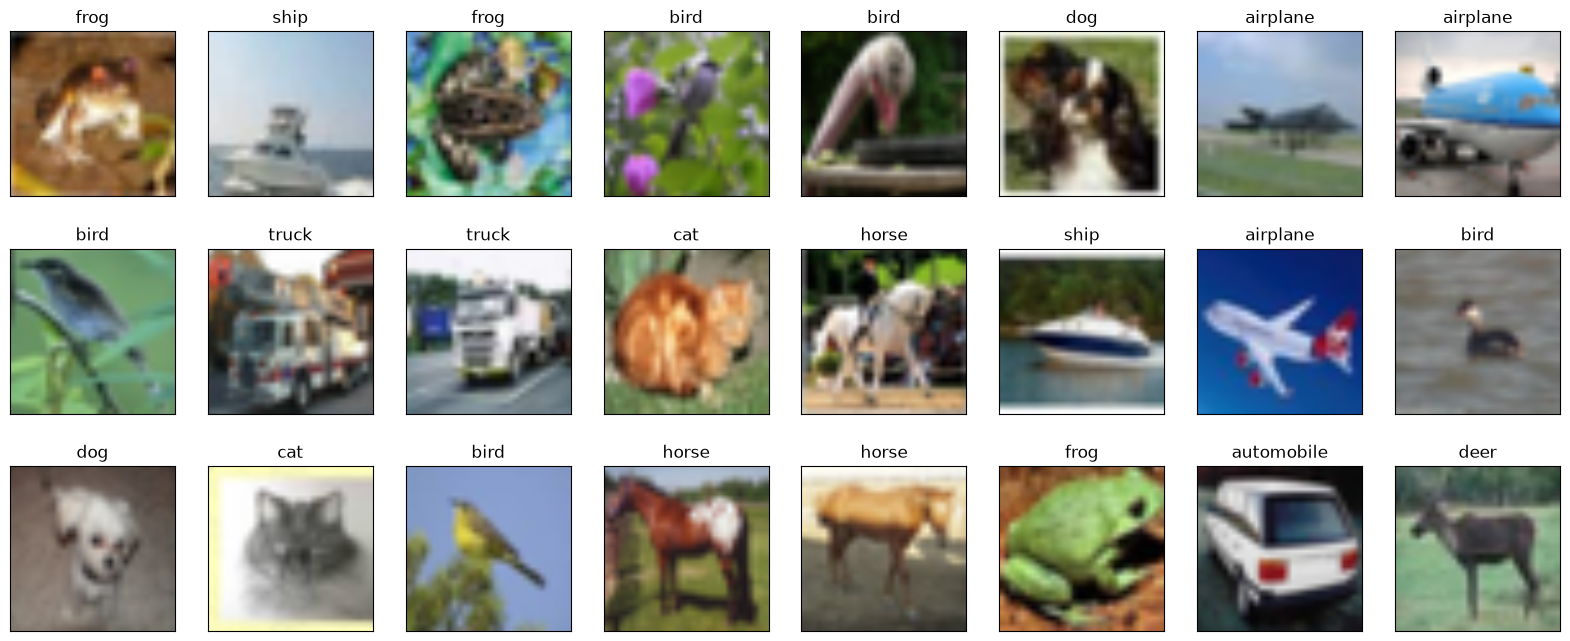

In [230]:
# Image samples
fig,axs = plt.subplots(3,8,figsize=(20,8), subplot_kw={'xticks': [], 'yticks': []})

for i,ax in enumerate(axs.flat):
    sample = train_val_data[i*100]
    sample_img = torch.transpose(torch.transpose(sample[0], 0, 2), 1, 0)
    sample_label = train_val_data.classes[sample[1]]
    ax.set_title(sample_label)
    ax.imshow(sample_img, interpolation='bilinear')

plt.show()

In [175]:
# Initialize Learning Curves list
cifar10_learning_curves = []

In [231]:
# Define function to initialize with He
def he_init(module):
    if isinstance(module, nn.Linear):
        nn.init.kaiming_uniform_(module.weight)
        nn.init.zeros_(module.bias)

# Define classifier
class CIFAR10Classifier(nn.Module):
    def __init__(self, n_features, n_classes, n_units, activation = nn.SiLU()):
        super().__init__()
        self.model = nn.Sequential(
            nn.Flatten(),
            nn.Linear(n_features, n_units), activation,
            nn.Linear(100, n_units), activation,
            nn.Linear(100, n_units), activation,
            nn.Linear(100, n_units), activation,
            nn.Linear(100, n_units), activation,
            nn.Linear(100, n_units), activation,
            nn.Linear(100, n_units), activation,
            nn.Linear(100, n_units), activation,
            nn.Linear(100, n_units), activation,
            nn.Linear(100, n_units), activation,
            nn.Linear(100, n_units), activation,
            nn.Linear(100, n_units), activation,
            nn.Linear(100, n_units), activation,
            nn.Linear(100, n_units), activation,
            nn.Linear(100, n_units), activation,
            nn.Linear(100, n_units), activation,
            nn.Linear(100, n_units), activation,
            nn.Linear(100, n_units), activation,
            nn.Linear(100, n_units), activation,
            nn.Linear(100, n_units), activation,
            nn.Linear(100, n_classes)
        )

    def forward(self, X):
        return self.model(X)
    
loss_dnn = nn.CrossEntropyLoss()

In [232]:
# Define Minibatch training with early stopping

import copy

def train_mbgd_early_stop(model, train_loader, val_loader, optimizer, criterion, n_epochs, device='mps', early_stop_threshold=1e-4, early_stop_patience=10):
    learning_curve = []
    best_val_loss = np.inf
    best_model_wts = copy.deepcopy(model.state_dict())
    wait = 0
    for epoch in range(n_epochs):
        # Training loss
        model.train()
        training_loss = 0.0
        for X_mb, y_mb in train_loader:
            X_mb, y_mb = X_mb.to(device), y_mb.to(device)
            y_pred = model(X_mb)
            loss = criterion(y_pred, y_mb)
            training_loss += loss.detach().item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
        training_loss /= len(train_loader)
                
        # Validation loss
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_val_mb, y_val_mb in val_loader:
                X_val_mb, y_val_mb = X_val_mb.to(device), y_val_mb.to(device)
                y_val_pred = model(X_val_mb)
                val_loss_mb = criterion(y_val_pred, y_val_mb)
                val_loss += val_loss_mb
            val_loss /= len(val_loader)
            learning_curve.append(val_loss)

        print(f'Epoch {epoch}/{n_epochs} | Training loss: {training_loss} | Validation loss: {val_loss}')
            
        if val_loss < best_val_loss - early_stop_threshold:
            best_val_loss, wait = val_loss, 0
            best_model_wts = copy.deepcopy(model.state_dict())
            
        else:
            wait += 1
            if wait >= early_stop_patience:
                print(f"Early stopping triggered at epoch {epoch}")
                break

    model.load_state_dict(best_model_wts)
    return learning_curve

In [233]:
# Trial 1
learning_rate = 5e-4
torch.manual_seed(42)
model_dnn = CIFAR10Classifier(n_features, n_classes, 100).to(device)
model_dnn.apply(he_init)
optimizer_dnn = torch.optim.NAdam(model_dnn.parameters(), betas=(0.9, 0.999), lr=learning_rate)
loss_dnn = nn.CrossEntropyLoss()
cifar10_learning_curves.append({
    'lr': learning_rate,
    'batch_norm': False,
    'activation': 'Swish',
    'initialization': 'He',
    'dropout': None,
    'values': train_mbgd_early_stop(model_dnn, cifar10_train_loader, cifar10_val_loader, optimizer_dnn, loss_dnn, 60, early_stop_patience=10)
})

Epoch 0/60 | Training loss: 2.0068685589060347 | Validation loss: 1.8124176263809204
Epoch 1/60 | Training loss: 1.787613397891757 | Validation loss: 1.7271593809127808
Epoch 2/60 | Training loss: 1.6737268411613306 | Validation loss: 1.7624859809875488
Epoch 3/60 | Training loss: 1.6010463178454346 | Validation loss: 1.728769302368164
Epoch 4/60 | Training loss: 1.5513418622277861 | Validation loss: 1.6657440662384033
Epoch 5/60 | Training loss: 1.5127675043579187 | Validation loss: 1.5627548694610596
Epoch 6/60 | Training loss: 1.4820823602923792 | Validation loss: 1.578068494796753
Epoch 7/60 | Training loss: 1.4574240547761734 | Validation loss: 1.5313186645507812
Epoch 8/60 | Training loss: 1.4301784576129304 | Validation loss: 1.5489017963409424
Epoch 9/60 | Training loss: 1.407560484961745 | Validation loss: 1.5509082078933716
Epoch 10/60 | Training loss: 1.3872675513577275 | Validation loss: 1.5315303802490234
Epoch 11/60 | Training loss: 1.3694676608588565 | Validation loss: 1

In [181]:
learning_rate = 1e-4
torch.manual_seed(42)
model_dnn = CIFAR10Classifier(n_features, n_classes, 100).to(device)
model_dnn.apply(he_init)
optimizer_dnn = torch.optim.NAdam(model_dnn.parameters(), betas=(0.9, 0.999), lr=learning_rate)
loss_dnn = nn.CrossEntropyLoss()
cifar10_learning_curves.append({
    'lr': learning_rate,
    'batch_norm': False,
    'activation': 'Swish',
    'initialization': 'He',
    'dropout': None,
    'values': train_mbgd_early_stop(model_dnn, cifar10_train_loader, cifar10_val_loader, optimizer_dnn, loss_dnn, 60, early_stop_patience=10)
})

Epoch 0/60 | Training loss: 1.9855249731271252 | Validation loss: 1.7970384359359741
Epoch 1/60 | Training loss: 1.755737227841142 | Validation loss: 1.7083845138549805
Epoch 2/60 | Training loss: 1.6476828011537836 | Validation loss: 1.6223258972167969
Epoch 3/60 | Training loss: 1.5785049469486228 | Validation loss: 1.5886236429214478
Epoch 4/60 | Training loss: 1.5304579375564586 | Validation loss: 1.5877772569656372
Epoch 5/60 | Training loss: 1.4889306515857694 | Validation loss: 1.5303733348846436
Epoch 6/60 | Training loss: 1.4555445846379353 | Validation loss: 1.562812328338623
Epoch 7/60 | Training loss: 1.4265589062932034 | Validation loss: 1.4961650371551514
Epoch 8/60 | Training loss: 1.3965437640174534 | Validation loss: 1.4800447225570679
Epoch 9/60 | Training loss: 1.3721906813900777 | Validation loss: 1.5031774044036865
Epoch 10/60 | Training loss: 1.3442774472629762 | Validation loss: 1.494394302368164
Epoch 11/60 | Training loss: 1.3229399009977747 | Validation loss: 

In [182]:
learning_rate = 5e-5
torch.manual_seed(42)
model_dnn = CIFAR10Classifier(n_features, n_classes, 100).to(device)
model_dnn.apply(he_init)
optimizer_dnn = torch.optim.NAdam(model_dnn.parameters(), betas=(0.9, 0.999), lr=learning_rate)
loss_dnn = nn.CrossEntropyLoss()
cifar10_learning_curves.append({
    'lr': learning_rate,
    'batch_norm': False,
    'activation': 'Swish',
    'initialization': 'He',
    'dropout': None,
    'values': train_mbgd_early_stop(model_dnn, cifar10_train_loader, cifar10_val_loader, optimizer_dnn, loss_dnn, 60, early_stop_patience=10)
})

Epoch 0/60 | Training loss: 2.0140723891519197 | Validation loss: 1.8473936319351196
Epoch 1/60 | Training loss: 1.7845543248482265 | Validation loss: 1.7255058288574219
Epoch 2/60 | Training loss: 1.6885760299008876 | Validation loss: 1.702932357788086
Epoch 3/60 | Training loss: 1.6287545164849797 | Validation loss: 1.6321722269058228
Epoch 4/60 | Training loss: 1.5802176095275229 | Validation loss: 1.672424554824829
Epoch 5/60 | Training loss: 1.5388518293952806 | Validation loss: 1.5931261777877808
Epoch 6/60 | Training loss: 1.506330804529983 | Validation loss: 1.5912996530532837
Epoch 7/60 | Training loss: 1.4783849844122576 | Validation loss: 1.529310941696167
Epoch 8/60 | Training loss: 1.4524295040708786 | Validation loss: 1.5349763631820679
Epoch 9/60 | Training loss: 1.4306672306965664 | Validation loss: 1.5424789190292358
Epoch 10/60 | Training loss: 1.4109571180448688 | Validation loss: 1.4940177202224731
Epoch 11/60 | Training loss: 1.3920171888652386 | Validation loss: 1

In [187]:
learning_rate = 7.5e-5
torch.manual_seed(42)
model_dnn = CIFAR10Classifier(n_features, n_classes, 100).to(device)
model_dnn.apply(he_init)
optimizer_dnn = torch.optim.NAdam(model_dnn.parameters(), betas=(0.9, 0.999), lr=learning_rate)
loss_dnn = nn.CrossEntropyLoss()
cifar10_learning_curves.append({
    'lr': learning_rate,
    'batch_norm': False,
    'activation': 'Swish',
    'initialization': 'He',
    'dropout': None,
    'values': train_mbgd_early_stop(model_dnn, cifar10_train_loader, cifar10_val_loader, optimizer_dnn, loss_dnn, 60, early_stop_patience=10)
})

Epoch 0/60 | Training loss: 1.9767449826489294 | Validation loss: 1.876861333847046
Epoch 1/60 | Training loss: 1.7474029281923935 | Validation loss: 1.6807173490524292
Epoch 2/60 | Training loss: 1.6554821293321837 | Validation loss: 1.6646778583526611
Epoch 3/60 | Training loss: 1.5915004626689604 | Validation loss: 1.6414785385131836
Epoch 4/60 | Training loss: 1.543046618744932 | Validation loss: 1.595357060432434
Epoch 5/60 | Training loss: 1.5051559150091876 | Validation loss: 1.5422172546386719
Epoch 6/60 | Training loss: 1.4747736334546542 | Validation loss: 1.6487854719161987
Epoch 7/60 | Training loss: 1.4516005999836925 | Validation loss: 1.514495611190796
Epoch 8/60 | Training loss: 1.4250191878831886 | Validation loss: 1.4879621267318726
Epoch 9/60 | Training loss: 1.4040809998549548 | Validation loss: 1.498803973197937
Epoch 10/60 | Training loss: 1.3807220466609702 | Validation loss: 1.4809256792068481
Epoch 11/60 | Training loss: 1.3640177752756446 | Validation loss: 1.

In [188]:
learning_rate = 2.5e-4
torch.manual_seed(42)
model_dnn = CIFAR10Classifier(n_features, n_classes, 100).to(device)
model_dnn.apply(he_init)
optimizer_dnn = torch.optim.NAdam(model_dnn.parameters(), betas=(0.9, 0.999), lr=learning_rate)
loss_dnn = nn.CrossEntropyLoss()
cifar10_learning_curves.append({
    'lr': learning_rate,
    'batch_norm': False,
    'activation': 'Swish',
    'initialization': 'He',
    'dropout': None,
    'values': train_mbgd_early_stop(model_dnn, cifar10_train_loader, cifar10_val_loader, optimizer_dnn, loss_dnn, 60, early_stop_patience=10)
})

Epoch 0/60 | Training loss: 2.012008972005295 | Validation loss: 1.85220205783844
Epoch 1/60 | Training loss: 1.7489420083201177 | Validation loss: 1.7076557874679565
Epoch 2/60 | Training loss: 1.6306582288108316 | Validation loss: 1.6023329496383667
Epoch 3/60 | Training loss: 1.5517311367314168 | Validation loss: 1.6298168897628784
Epoch 4/60 | Training loss: 1.5006429971577686 | Validation loss: 1.5892804861068726
Epoch 5/60 | Training loss: 1.459432349149098 | Validation loss: 1.5276800394058228
Epoch 6/60 | Training loss: 1.4257856042739256 | Validation loss: 1.5303926467895508
Epoch 7/60 | Training loss: 1.3970440269024895 | Validation loss: 1.4870482683181763
Epoch 8/60 | Training loss: 1.3665528848566058 | Validation loss: 1.4796473979949951
Epoch 9/60 | Training loss: 1.3397662461693607 | Validation loss: 1.5031089782714844
Epoch 10/60 | Training loss: 1.3116618040273946 | Validation loss: 1.4828494787216187
Epoch 11/60 | Training loss: 1.288906786529918 | Validation loss: 1.

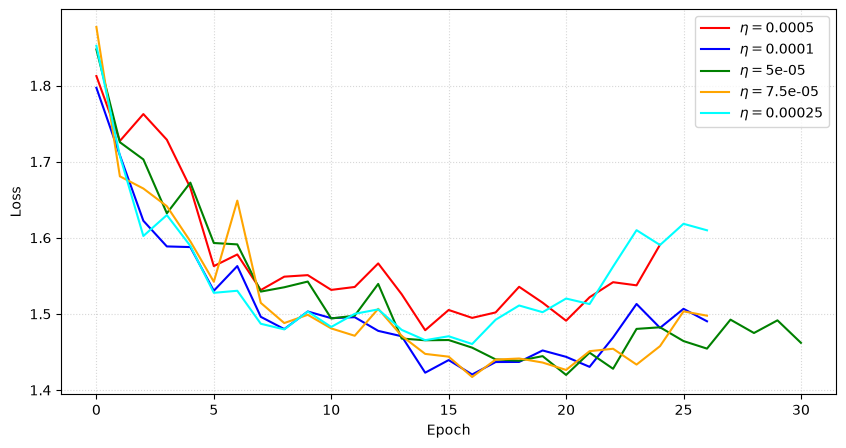

In [236]:
# Plot Learning Curves
plt.figure(figsize=(10,5))
colors = ['red', 'blue', 'green', 'orange', 'cyan']
for i,curve in enumerate(cifar10_learning_curves):
    v = [val.to('cpu') for val in curve['values']]
    h = range(len(v))
    plt.plot(h,v,color=colors[i],label=rf'$\eta=${curve['lr']}')

plt.grid(visible=True, axis='both', ls=':', alpha=0.5)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [237]:
# Select (roughly) best learning rate
learning_rate = 1e-4
torch.manual_seed(42)
model_dnn = CIFAR10Classifier(n_features, n_classes, 100).to(device)
model_dnn.apply(he_init)
optimizer_dnn = torch.optim.NAdam(model_dnn.parameters(), betas=(0.9, 0.999), lr=learning_rate)
loss_dnn = nn.CrossEntropyLoss()
lc1 = train_mbgd_early_stop(model_dnn, cifar10_train_loader, cifar10_val_loader, optimizer_dnn, loss_dnn, 60, early_stop_patience=10)
cifar10_metric = Accuracy(task="multiclass", num_classes=n_classes).to(device)
val_score_1 = evaluate_tm(model_dnn, cifar10_val_loader, cifar10_metric)
print(f'Validation score: {val_score_1: .2%}')

Epoch 0/60 | Training loss: 1.9855249731271252 | Validation loss: 1.7970384359359741
Epoch 1/60 | Training loss: 1.755737227841142 | Validation loss: 1.7083845138549805
Epoch 2/60 | Training loss: 1.6476828011537836 | Validation loss: 1.6223258972167969
Epoch 3/60 | Training loss: 1.5785049469486228 | Validation loss: 1.5886236429214478
Epoch 4/60 | Training loss: 1.5304579375564586 | Validation loss: 1.5877772569656372
Epoch 5/60 | Training loss: 1.4889306515857694 | Validation loss: 1.5303733348846436
Epoch 6/60 | Training loss: 1.4555445846379353 | Validation loss: 1.562812328338623
Epoch 7/60 | Training loss: 1.4265589062932034 | Validation loss: 1.4961650371551514
Epoch 8/60 | Training loss: 1.3965437640174534 | Validation loss: 1.4800447225570679
Epoch 9/60 | Training loss: 1.3721906813900777 | Validation loss: 1.5031774044036865
Epoch 10/60 | Training loss: 1.3442774472629762 | Validation loss: 1.494394302368164
Epoch 11/60 | Training loss: 1.3229399009977747 | Validation loss: 

In [292]:
# CIFAR10 Classifier V2 - with batch norm and cleaner code
class DenseV2(nn.Module):
    def __init__(self, n_in, n_out, activation = nn.SiLU(), batch_norm=False, momentum=0.01, p=0.0):
        super().__init__()
        layers = []
        if batch_norm:
            layers.append(nn.BatchNorm1d(n_in, momentum=momentum))

        layers += [nn.Linear(n_in, n_out), activation]

        if p > 0.0:
            layers.append(nn.AlphaDropout(p=p))

        self.model = nn.Sequential(*layers)

    def forward(self, X):
        return self.model(X)

class CIFAR10ClassifierV2(nn.Module):
    def __init__(self, 
                 n_features,
                 n_classes,
                 n_layers,
                 n_units,
                 activation = nn.SiLU(),
                 batch_norm=False,
                 momentum=0.01,
                 p=None):
        super().__init__()
        if p is None:
            p = n_units * [0.0]
        
        self.model = nn.Sequential(
            nn.Flatten(),
            DenseV2(n_features, 
                    n_units, 
                    activation=activation, 
                    batch_norm=batch_norm, 
                    momentum=momentum, p=p[0])
        )
        
        if n_layers > 1:
            for p_ in p[1:]:
                self.model.append(DenseV2(n_units, 
                                          n_units,
                                          activation=activation,
                                          batch_norm=batch_norm,
                                          momentum=momentum, p=p_)
                                 )
        
        if batch_norm:
            self.model.append(nn.BatchNorm1d(n_units, momentum=momentum))
            
        self.model.append(nn.Linear(n_units,n_classes))

    def forward(self, X):
        return self.model(X)

In [272]:
# Best learning rate with batch norm (ballpark)
learning_rate = 1.0e-3
torch.manual_seed(42)
model_dnn = CIFAR10ClassifierV2(n_features, n_classes, 20, 100, batch_norm=True).to(device)
model_dnn.apply(he_init)
optimizer_dnn = torch.optim.NAdam(model_dnn.parameters(), betas=(0.9, 0.999), lr=learning_rate)
loss_dnn = nn.CrossEntropyLoss()
lc2 = train_mbgd_early_stop(model_dnn, cifar10_train_loader, cifar10_val_loader, optimizer_dnn, loss_dnn, 60, early_stop_patience=10)
cifar10_metric = Accuracy(task="multiclass", num_classes=n_classes).to(device)
val_score_2 = evaluate_tm(model_dnn, cifar10_val_loader, cifar10_metric)
print(f'Validation score: {val_score_2: .2%}')

Epoch 0/60 | Training loss: 2.204086219239252 | Validation loss: 1.947129726409912
Epoch 1/60 | Training loss: 1.924365164798121 | Validation loss: 1.7699933052062988
Epoch 2/60 | Training loss: 1.8338484790364138 | Validation loss: 1.7453951835632324
Epoch 3/60 | Training loss: 1.7817019400396665 | Validation loss: 1.6763601303100586
Epoch 4/60 | Training loss: 1.7338386486842434 | Validation loss: 1.6580402851104736
Epoch 5/60 | Training loss: 1.700189784137425 | Validation loss: 1.6323679685592651
Epoch 6/60 | Training loss: 1.666697855527806 | Validation loss: 1.5855963230133057
Epoch 7/60 | Training loss: 1.6322084140845368 | Validation loss: 1.535899043083191
Epoch 8/60 | Training loss: 1.6101253027600775 | Validation loss: 1.5223932266235352
Epoch 9/60 | Training loss: 1.5736430597881435 | Validation loss: 1.533839464187622
Epoch 10/60 | Training loss: 1.5467249303314816 | Validation loss: 1.4884403944015503
Epoch 11/60 | Training loss: 1.52127691902162 | Validation loss: 1.4957

In [281]:
# Using SELU
# Apply Lecun Init
def apply_lecun_init(module):
    if isinstance(module, nn.Linear):
        fan_in = module.in_features
        std = np.sqrt(1/fan_in)
        nn.init.normal_(module.weight, std=std)
        nn.init.zeros_(module.bias)

# Standardize inputs
cifar10_means = (train_val_data.data[train_data.indices]/255.0).mean(axis=(0, 1, 2))
cifar10_stds = (train_val_data.data[train_data.indices]/255.0).std(axis=(0, 1, 2))

transform_n = T.Compose([T.ToImage(), 
                         T.ToDtype(torch.float32, scale=True), 
                         T.Normalize(cifar10_means.tolist(), cifar10_stds.tolist())])

torch.manual_seed(42)
train_val_data_n = datasets.CIFAR10(root=Path.cwd().joinpath('data'), download=True, train=True, transform=transform_n)
test_data_n = datasets.CIFAR10(root=Path.cwd().joinpath('data'), download=True, transform=transform_n)

train_loader_n = DataLoader(torch.utils.data.Subset(train_val_data_n, train_data.indices), batch_size=32, shuffle=True)
val_loader_n = DataLoader(torch.utils.data.Subset(train_val_data_n, val_data.indices), batch_size=32)
test_loader_n = DataLoader(test_data_n, batch_size=32)

learning_rate = 2.5e-4
model_dnn = CIFAR10ClassifierV2(n_features, n_classes, 20, 100, activation=nn.SELU()).to(device)
model_dnn.apply(apply_lecun_init)
optimizer_dnn = torch.optim.NAdam(model_dnn.parameters(), betas=(0.9, 0.999), lr=learning_rate)
loss_dnn = nn.CrossEntropyLoss()
lc3 = train_mbgd_early_stop(model_dnn, train_loader_n, val_loader_n, optimizer_dnn, loss_dnn, 60, early_stop_patience=10)
cifar10_metric = Accuracy(task="multiclass", num_classes=n_classes).to(device)
val_score_3 = evaluate_tm(model_dnn, val_loader_n, cifar10_metric)
print(f'Validation score: {val_score_3: .2%}')

Epoch 0/60 | Training loss: 1.8522629434535414 | Validation loss: 1.7143181562423706
Epoch 1/60 | Training loss: 1.6693390062199303 | Validation loss: 1.6163438558578491
Epoch 2/60 | Training loss: 1.5832299066928572 | Validation loss: 1.571581482887268
Epoch 3/60 | Training loss: 1.523114742839599 | Validation loss: 1.5397582054138184
Epoch 4/60 | Training loss: 1.4757514302410297 | Validation loss: 1.5216312408447266
Epoch 5/60 | Training loss: 1.4356664222186561 | Validation loss: 1.4800541400909424
Epoch 6/60 | Training loss: 1.4032631929495187 | Validation loss: 1.4783713817596436
Epoch 7/60 | Training loss: 1.3717868126446928 | Validation loss: 1.4681499004364014
Epoch 8/60 | Training loss: 1.340426775184013 | Validation loss: 1.4576234817504883
Epoch 9/60 | Training loss: 1.3152346626273606 | Validation loss: 1.458696722984314
Epoch 10/60 | Training loss: 1.287401895194335 | Validation loss: 1.437790870666504
Epoch 11/60 | Training loss: 1.2683735985491575 | Validation loss: 1.4

In [308]:
# Using SELU - with Alpha Dropout
cifar10_metric = Accuracy(task="multiclass", num_classes=n_classes).to(device)

def objective(trial):
    learning_rate = trial.suggest_float('learning_rate', 5e-5, 5e-4, log=True)
    dropout_layers = trial.suggest_int('dropout_layers', 1, 8)
    p_list = (20 - dropout_layers) * [0] + dropout_layers * [0.1]
    torch.manual_seed(42)
    model_dnn = CIFAR10ClassifierV2(n_features, n_classes, 20, 100, activation=nn.SELU(), p=p_list).to(device)
    model_dnn.apply(apply_lecun_init)
    optimizer_dnn = torch.optim.NAdam(model_dnn.parameters(), betas=(0.9, 0.999), lr=learning_rate)
    loss_dnn = nn.CrossEntropyLoss()
    lc4 = train_mbgd_early_stop(model_dnn, train_loader_n, val_loader_n, optimizer_dnn, loss_dnn, 60, early_stop_patience=10)
    val_score_4 = evaluate_tm(model_dnn, val_loader_n, cifar10_metric)
    return val_score_4

sampler = optuna.samplers.TPESampler(seed=42)
study = optuna.create_study(direction="maximize", sampler=sampler)
study.optimize(objective, n_trials=5)

[I 2026-11-08 22:21:31,795] A new study created in memory with name: no-name-a1703d59-e8fe-4e6c-a8a4-ee5561bb169e


Epoch 0/60 | Training loss: 2.1093492269854894 | Validation loss: 1.9556145668029785
Epoch 1/60 | Training loss: 1.8013876915486382 | Validation loss: 1.8448089361190796
Epoch 2/60 | Training loss: 1.6698411692942638 | Validation loss: 1.7958613634109497
Epoch 3/60 | Training loss: 1.584833665104224 | Validation loss: 1.7657991647720337
Epoch 4/60 | Training loss: 1.5222516628386031 | Validation loss: 1.736204743385315
Epoch 5/60 | Training loss: 1.4732167038751478 | Validation loss: 1.7322529554367065
Epoch 6/60 | Training loss: 1.4263868717411858 | Validation loss: 1.803644061088562
Epoch 7/60 | Training loss: 1.384557786865614 | Validation loss: 1.7332754135131836
Epoch 8/60 | Training loss: 1.343073848679969 | Validation loss: 1.782403588294983
Epoch 9/60 | Training loss: 1.3033889502011553 | Validation loss: 1.8610661029815674
Epoch 10/60 | Training loss: 1.271452924632484 | Validation loss: 1.8068703413009644
Epoch 11/60 | Training loss: 1.2381117298574251 | Validation loss: 1.88

[I 2026-11-08 22:24:32,142] Trial 0 finished with value: 0.46160000562667847 and parameters: {'learning_rate': 0.00011844319751820405, 'dropout_layers': 8}. Best is trial 0 with value: 0.46160000562667847.


Epoch 0/60 | Training loss: 1.9688540972456834 | Validation loss: 1.7952982187271118
Epoch 1/60 | Training loss: 1.6903056828536798 | Validation loss: 1.762998104095459
Epoch 2/60 | Training loss: 1.5825431958614042 | Validation loss: 1.6078181266784668
Epoch 3/60 | Training loss: 1.5051325076678668 | Validation loss: 1.681304693222046
Epoch 4/60 | Training loss: 1.4432098901517525 | Validation loss: 1.5938912630081177
Epoch 5/60 | Training loss: 1.3856437060116196 | Validation loss: 1.679370641708374
Epoch 6/60 | Training loss: 1.3484820818002967 | Validation loss: 1.6935784816741943
Epoch 7/60 | Training loss: 1.298815859618048 | Validation loss: 1.7138850688934326
Epoch 8/60 | Training loss: 1.2619067631296512 | Validation loss: 1.6965326070785522
Epoch 9/60 | Training loss: 1.224909507431879 | Validation loss: 1.7616164684295654
Epoch 10/60 | Training loss: 1.1911448145387185 | Validation loss: 1.7260003089904785
Epoch 11/60 | Training loss: 1.1593133707205794 | Validation loss: 1.

[I 2026-11-08 22:27:16,760] Trial 1 finished with value: 0.462799996137619 and parameters: {'learning_rate': 0.00026975154833351167, 'dropout_layers': 5}. Best is trial 1 with value: 0.462799996137619.


Epoch 0/60 | Training loss: 1.9594748883528665 | Validation loss: 1.7157888412475586
Epoch 1/60 | Training loss: 1.686221570772064 | Validation loss: 1.6362184286117554
Epoch 2/60 | Training loss: 1.5648311822229697 | Validation loss: 1.5849043130874634
Epoch 3/60 | Training loss: 1.4849779925281983 | Validation loss: 1.5743257999420166
Epoch 4/60 | Training loss: 1.4211033722485051 | Validation loss: 1.5568429231643677
Epoch 5/60 | Training loss: 1.3667033951419758 | Validation loss: 1.5638116598129272
Epoch 6/60 | Training loss: 1.3205523090999687 | Validation loss: 1.5742642879486084
Epoch 7/60 | Training loss: 1.2795878095498048 | Validation loss: 1.5220940113067627
Epoch 8/60 | Training loss: 1.2355165533250159 | Validation loss: 1.5380560159683228
Epoch 9/60 | Training loss: 1.1977205317157673 | Validation loss: 1.5934579372406006
Epoch 10/60 | Training loss: 1.1635604036896467 | Validation loss: 1.5862345695495605
Epoch 11/60 | Training loss: 1.1314945563239753 | Validation loss

[I 2026-11-08 22:30:30,677] Trial 2 finished with value: 0.5005999803543091 and parameters: {'learning_rate': 7.161246859115129e-05, 'dropout_layers': 2}. Best is trial 2 with value: 0.5005999803543091.


Epoch 0/60 | Training loss: 2.1866551193686012 | Validation loss: 2.0399186611175537
Epoch 1/60 | Training loss: 1.8892930807081112 | Validation loss: 1.964174509048462
Epoch 2/60 | Training loss: 1.7447590238249886 | Validation loss: 1.8792564868927002
Epoch 3/60 | Training loss: 1.659534098158174 | Validation loss: 1.8263756036758423
Epoch 4/60 | Training loss: 1.584144343487659 | Validation loss: 1.7943525314331055
Epoch 5/60 | Training loss: 1.529284332733927 | Validation loss: 1.7598026990890503
Epoch 6/60 | Training loss: 1.4816277076694757 | Validation loss: 1.741300344467163
Epoch 7/60 | Training loss: 1.4410991724196611 | Validation loss: 1.7471181154251099
Epoch 8/60 | Training loss: 1.4023778700794662 | Validation loss: 1.7346832752227783
Epoch 9/60 | Training loss: 1.3662712542656557 | Validation loss: 1.781379222869873
Epoch 10/60 | Training loss: 1.3311244136658473 | Validation loss: 1.7732139825820923
Epoch 11/60 | Training loss: 1.3015164763434355 | Validation loss: 1.8

[I 2026-11-08 22:34:02,122] Trial 3 finished with value: 0.46480000019073486 and parameters: {'learning_rate': 5.715491938156613e-05, 'dropout_layers': 7}. Best is trial 2 with value: 0.5005999803543091.


Epoch 0/60 | Training loss: 2.005762959001076 | Validation loss: 1.8279963731765747
Epoch 1/60 | Training loss: 1.7141926159821423 | Validation loss: 1.7567418813705444
Epoch 2/60 | Training loss: 1.5962236634619116 | Validation loss: 1.6720993518829346
Epoch 3/60 | Training loss: 1.5232780510513344 | Validation loss: 1.6596734523773193
Epoch 4/60 | Training loss: 1.4555519179579377 | Validation loss: 1.613088846206665
Epoch 5/60 | Training loss: 1.4002470277096248 | Validation loss: 1.6393500566482544
Epoch 6/60 | Training loss: 1.3595615894386086 | Validation loss: 1.7175427675247192
Epoch 7/60 | Training loss: 1.316874286936968 | Validation loss: 1.6473305225372314
Epoch 8/60 | Training loss: 1.2721258173534526 | Validation loss: 1.61501145362854
Epoch 9/60 | Training loss: 1.2393146447450791 | Validation loss: 1.7659733295440674
Epoch 10/60 | Training loss: 1.2031529313635132 | Validation loss: 1.6887216567993164
Epoch 11/60 | Training loss: 1.1735021657950504 | Validation loss: 1.

[I 2026-11-08 22:36:48,732] Trial 4 finished with value: 0.46880000829696655 and parameters: {'learning_rate': 0.00019956529392808388, 'dropout_layers': 6}. Best is trial 2 with value: 0.5005999803543091.


In [311]:
learning_rate, dropout_layers = study.best_params.values()
p_list = (20 - dropout_layers) * [0] + dropout_layers * [0.1]
torch.manual_seed(42)
model_dnn = CIFAR10ClassifierV2(n_features, n_classes, 20, 100, activation=nn.SELU(), p=p_list).to(device)
model_dnn.apply(apply_lecun_init)
optimizer_dnn = torch.optim.NAdam(model_dnn.parameters(), betas=(0.9, 0.999), lr=learning_rate)
loss_dnn = nn.CrossEntropyLoss()
lc4 = train_mbgd_early_stop(model_dnn, train_loader_n, val_loader_n, optimizer_dnn, loss_dnn, 60, early_stop_patience=10)
val_score_4 = evaluate_tm(model_dnn, val_loader_n, cifar10_metric)

Epoch 0/60 | Training loss: 1.9594748883528665 | Validation loss: 1.7157888412475586
Epoch 1/60 | Training loss: 1.686221570772064 | Validation loss: 1.6362184286117554
Epoch 2/60 | Training loss: 1.5648311822229697 | Validation loss: 1.5849043130874634
Epoch 3/60 | Training loss: 1.4849779925281983 | Validation loss: 1.5743257999420166
Epoch 4/60 | Training loss: 1.4211033722485051 | Validation loss: 1.5568429231643677
Epoch 5/60 | Training loss: 1.3667033951419758 | Validation loss: 1.5638116598129272
Epoch 6/60 | Training loss: 1.3205523090999687 | Validation loss: 1.5742642879486084
Epoch 7/60 | Training loss: 1.2795878095498048 | Validation loss: 1.5220940113067627
Epoch 8/60 | Training loss: 1.2355165533250159 | Validation loss: 1.5380560159683228
Epoch 9/60 | Training loss: 1.1977205317157673 | Validation loss: 1.5934579372406006
Epoch 10/60 | Training loss: 1.1635604036896467 | Validation loss: 1.5862345695495605
Epoch 11/60 | Training loss: 1.1314945563239753 | Validation loss

In [312]:
print(f'Validation accuracy: {val_score_4: .2%}')

Validation accuracy:  50.06%


In [316]:
# Using MCDropout - without retraining
def evaluate_mcdropout(model, val_loader, metric_fn):
    model.eval()
    metric_fn.reset()
    for module in model.modules():
        if isinstance(module, nn.AlphaDropout):
            module.train()
    
    with torch.no_grad():
        for X_mb, y_mb in val_loader:
            X_mb, y_mb = X_mb.to(device), y_mb.to(device)
            X_mb_repeated = X_mb.repeat_interleave(100, dim=0)
            y_logits_all = model(X_mb_repeated).reshape(len(X_mb), 100, n_classes)
            y_probas_all = F.softmax(y_logits_all, dim=-1)
            y_probas = y_probas_all.mean(dim=1)
            y_pred = y_probas.argmax(dim=-1)
            metric_fn.update(y_pred, y_mb)
    return metric_fn.compute()

val_score_4_mcdropout = evaluate_mcdropout(model_dnn, val_loader_n, cifar10_metric)
print(f'Accuracy with mcdropout: {val_score_4_mcdropout:.2%}')

Accuracy with mcdropout: 49.96%


In [318]:
# Training with learning rate schedule
def train_mbgd_scheduled_early_stop(model, 
                                    train_loader, 
                                    val_loader, 
                                    optimizer, 
                                    scheduler, 
                                    criterion, 
                                    n_epochs, 
                                    device='mps', 
                                    early_stop_threshold=1e-4, 
                                    early_stop_patience=10):
    learning_curve = []
    best_val_loss = np.inf
    best_model_wts = copy.deepcopy(model.state_dict())
    wait = 0
    for epoch in range(n_epochs):
        # Training loss
        model.train()
        training_loss = 0.0
        for X_mb, y_mb in train_loader:
            X_mb, y_mb = X_mb.to(device), y_mb.to(device)
            y_pred = model(X_mb)
            loss = criterion(y_pred, y_mb)
            training_loss += loss.detach().item()
            loss.backward()
            optimizer.step()
            scheduler.step() #per documentation of 1cycle scheduler, step method must be called after every batch
            optimizer.zero_grad()
        training_loss /= len(train_loader)                
        # Validation loss
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_val_mb, y_val_mb in val_loader:
                X_val_mb, y_val_mb = X_val_mb.to(device), y_val_mb.to(device)
                y_val_pred = model(X_val_mb)
                val_loss_mb = criterion(y_val_pred, y_val_mb)
                val_loss += val_loss_mb
            val_loss /= len(val_loader)
            learning_curve.append(val_loss)

        print(f'Epoch {epoch}/{n_epochs} | Training loss: {training_loss} | Validation loss: {val_loss}')
            
        if val_loss < best_val_loss - early_stop_threshold:
            best_val_loss, wait = val_loss, 0
            best_model_wts = copy.deepcopy(model.state_dict())
            
        else:
            wait += 1
            if wait >= early_stop_patience:
                print(f"Early stopping triggered at epoch {epoch}")
                break

    model.load_state_dict(best_model_wts)
    return learning_curve

In [332]:
# Using 1Cycle Scheduling
learning_rate, dropout_layers = study.best_params.values()
p_list = (20 - dropout_layers) * [0] + dropout_layers * [0.1]
torch.manual_seed(42)
model_dnn = CIFAR10ClassifierV2(n_features, n_classes, 20, 100, activation=nn.SELU(), p=p_list).to(device)
model_dnn.apply(apply_lecun_init)
optimizer_dnn = torch.optim.NAdam(model_dnn.parameters(), betas=(0.9, 0.999), lr=learning_rate)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer_dnn, max_lr=learning_rate, epochs=60, steps_per_epoch=32, div_factor=10)
loss_dnn = nn.CrossEntropyLoss()
lc5 = train_mbgd_early_stop(model_dnn, train_loader_n, val_loader_n, optimizer_dnn, loss_dnn, 60, early_stop_patience=20)
val_score_5 = evaluate_tm(model_dnn, val_loader_n, cifar10_metric)

Epoch 0/60 | Training loss: 2.2923685221614445 | Validation loss: 1.9357622861862183
Epoch 1/60 | Training loss: 2.038286631210696 | Validation loss: 1.8326468467712402
Epoch 2/60 | Training loss: 1.9310657096908883 | Validation loss: 1.797723412513733
Epoch 3/60 | Training loss: 1.8567840354020662 | Validation loss: 1.7723767757415771
Epoch 4/60 | Training loss: 1.799627983917475 | Validation loss: 1.7447481155395508
Epoch 5/60 | Training loss: 1.7567223922191313 | Validation loss: 1.734542965888977
Epoch 6/60 | Training loss: 1.7203428142868888 | Validation loss: 1.7172480821609497
Epoch 7/60 | Training loss: 1.6857544198134475 | Validation loss: 1.7128099203109741
Epoch 8/60 | Training loss: 1.65568786190178 | Validation loss: 1.6984376907348633
Epoch 9/60 | Training loss: 1.62999234304584 | Validation loss: 1.699464201927185
Epoch 10/60 | Training loss: 1.6014493331895623 | Validation loss: 1.6997727155685425
Epoch 11/60 | Training loss: 1.5756623890693084 | Validation loss: 1.6925

In [333]:
print(f'Validation accuracy: {val_score_5:.2%}')

Validation accuracy: 44.86%


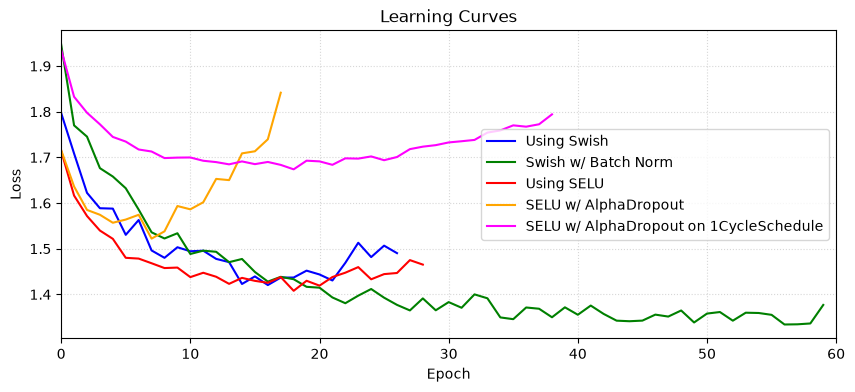

In [336]:
learning_curves = [lc1, lc2, lc3, lc4, lc5]
val_scores = [val_score_1, val_score_2, val_score_3, val_score_4, val_score_5]
names = ['Using Swish', 'Swish w/ Batch Norm', 'Using SELU', 'SELU w/ AlphaDropout', 'SELU w/ AlphaDropout on 1CycleSchedule']
colors = ['blue', 'green', 'red', 'orange', 'magenta']
plt.figure(figsize=(10,4))
for i,curve in enumerate(learning_curves):
    h = range(len(curve))
    v = [p.cpu() for p in curve]
    plt.plot(h, v, color=colors[i], label=names[i])

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Learning Curves')
plt.grid(visible=True, axis='both', ls=':', alpha=0.5)
plt.legend()
plt.xlim(0,60)
plt.show()

## Deep Computer Vision Using Convolutional Neural Networks

### Implementing Convolutional Layers with PyTorch

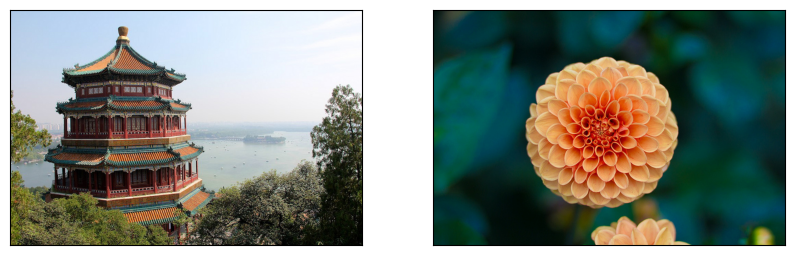

In [343]:
# Load Sample Images
from sklearn.datasets import load_sample_images

sample_images = np.stack(load_sample_images()['images'])
sample_images = torch.tensor(sample_images, dtype=torch.float32) / 255.0

fig,axs = plt.subplots(1,2, figsize=(10,5), subplot_kw=dict(xticks=[], yticks=[]))
for i,img in enumerate(sample_images):
    axs[i].imshow(img)

In [345]:
# Image details
shape = tuple(sample_images[0].shape)
height, width, n_channels = shape

print(f'Image shape: {shape}')
print(f'Height: {height}')
print(f'Weight: {width}')
print(f'Num Channels: {n_channels}')

Image shape: (427, 640, 3)
Height: 427
Weight: 640
Num Channels: 3
